# K5_m1p33 | Vegetation composition ordination

**Purpose.** Display the original 10-dimensional cover space as a 2D PCA, with observed plots, five K5 community centroids, and ten hypothetical pure-component (100% cover) vertices. This notebook **does not rerun fuzzy c-means** and does not require five membership columns.

**Statistical interpretation:** Centered, **unscaled** PCA of cover percentages; variables are *not* independently standardized, so their common physical scale is retained. Pure-cover vertices are hypothetical endpoints, not observed reference sites. The data are compositional if the ten classes form an exhaustive, disjoint partition; accordingly, PCA here is a visualization of Euclidean cover geometry, **not** a log-ratio analysis. PC projections compress an intrinsically higher-dimensional space. Cluster centroid markers describe the original fitted fuzzy clusters only when the saved centroid file can be unambiguously read.

Plots include a vertex/centroid ordination, a cleaner centroid-only overlay, and quantitative projection diagnostics. By default, figures display inline without writing files; set `EXPORT=True` to export publication-quality vector and raster figures and supporting tables.


In [13]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from IPython.display import display

# Adapt if the data repository has moved.
ROOT = Path(r"C:\NCA_DATA\Vegetation Data\Clustering_Veg")
PARENT_FILE = ROOT / "K5_m1p33" / "Derived" / "NCA_FCM_K5_m1p33_parent_assignments.csv"
CENTROID_FILE = ROOT / "K5_m1p33" / "Tables" / "K5_m1p33_parent_centroids_and_membership.csv"
OUTPUT_DIR = ROOT / "K5_m1p33_TabsFigs" / "Figures" / "Ordination"

EXPORT = False
MIN_TOTAL, MAX_TOTAL = 97.0, 103.0   # expected sum in percentage points
REQUIRE_CLOSURE = True               # fail if classes do not collectively cover 100%
SHOW_ALL_VERTICES = True
USE_MEMBERSHIP_ALPHA = True
POINT_SIZE = 16
MAX_PLOTTED_POINTS = None            # e.g. 2500 for deterministic display-only thinning
RANDOM_SEED = 31

FG_COLS = ["ARTR_FG","SHRUB_FG","PBG_FG","EAG_FG","EF_FG",
           "BAREGROUND_FG","BIOCRUST_FG","LITTER_FG","OTHER_FG","NPF_FG"]
FG_SHORT = {"ARTR_FG":"ARTR", "SHRUB_FG":"Non-ARTR shrub","PBG_FG":"PBG",
            "EAG_FG":"EAG","EF_FG":"Exotic forb","BAREGROUND_FG":"Bare ground",
            "BIOCRUST_FG":"Biocrust","LITTER_FG":"Litter",
            "OTHER_FG":"Other","NPF_FG":"Native perennial forb"}
CLUSTER_LABELS = {1:"PBG",2:"ARTR",3:"Non-ARTR shrub",4:"Exotic forb",5:"EAG"}
CLUSTER_COLORS = {1:"#0072B2",2:"#009E73",3:"#E69F00",4:"#CC79A7",5:"#D55E00"}
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,
                     "axes.spines.top":False,"axes.spines.right":False,
                     "pdf.fonttype":42,"svg.fonttype":"none"})
print("Parent:", PARENT_FILE)
print("Centroids:", CENTROID_FILE)


Parent: C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Derived\NCA_FCM_K5_m1p33_parent_assignments.csv
Centroids: C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33\Tables\K5_m1p33_parent_centroids_and_membership.csv


In [14]:
if not PARENT_FILE.exists():
    raise FileNotFoundError(f"Missing parent assignments: {PARENT_FILE}")
raw = pd.read_csv(PARENT_FILE, low_memory=False)
needed = ["parent_cluster_k5", *FG_COLS]
missing = sorted(set(needed) - set(raw.columns))
if missing:
    raise ValueError(f"Missing required columns: {missing}")

dat = raw.copy()
dat[FG_COLS] = dat[FG_COLS].apply(pd.to_numeric, errors="coerce")
dat["parent_cluster_k5"] = pd.to_numeric(dat["parent_cluster_k5"], errors="coerce")
valid = dat[FG_COLS + ["parent_cluster_k5"]].notna().all(axis=1)
print("Excluded incomplete records:", (~valid).sum())
dat = dat.loc[valid].copy()
dat["parent_cluster_k5"] = dat["parent_cluster_k5"].astype(int)
if not set(dat["parent_cluster_k5"].unique()).issubset(set(CLUSTER_LABELS)):
    raise ValueError("Unexpected parent cluster IDs")

if ((dat[FG_COLS] < -1e-9) | (dat[FG_COLS] > 100+1e-9)).any().any():
    raise ValueError("Cover values must be between 0 and 100 percent.")
tot = dat[FG_COLS].sum(axis=1)
summary = tot.describe()
display(summary.to_frame("cover total (%)"))
bad = ~tot.between(MIN_TOTAL, MAX_TOTAL)
print(f"Rows outside [{MIN_TOTAL}, {MAX_TOTAL}]%: {bad.sum()} / {len(dat)}")
if REQUIRE_CLOSURE and bad.any():
    raise ValueError("Cover categories are not closed near 100%. Inspect missing "
                     "categories, differing denominators, or units before plotting pure-cover vertices.")
if not REQUIRE_CLOSURE and bad.any():
    warnings.warn("Non-closed cover: pure-cover endpoints are still definable, "
                  "but simplex/mixing interpretation is not supported.")
print("Rows:", len(dat), " | Parent counts:", dat["parent_cluster_k5"].value_counts().sort_index().to_dict())


Excluded incomplete records: 0


,cover total (%)
count,1171.000000
mean,99.988830
std,0.110597
min,97.950000
25%,100.000000
50%,100.000000
75%,100.000000
max,102.483333


Rows outside [97.0, 103.0]%: 0 / 1171
Rows: 1171  | Parent counts: {1: 245, 2: 146, 3: 208, 4: 201, 5: 371}


## PCA with supplementary pure-cover vertices

Fit PCA **only to observations** (not synthetic endpoints). Transform ten 100%-cover endpoints using the *same fitted PCA*; do not fit a separate PCA to the endpoints. Under a closed 100%-cover partition, the entire projected data cloud must lie within the convex hull of projected pure-cover endpoints (up to numeric tolerance). A projected fitted centroid is likewise a weighted cover-space average, provided the fitted centroids use the same variables and scale.


In [15]:
X = dat[FG_COLS].to_numpy(dtype=float)
pca = PCA(n_components=10, svd_solver="full").fit(X)
scores = pca.transform(X)[:, :2]
dat["PC1"],dat["PC2"] = scores[:,0],scores[:,1]
V = np.eye(len(FG_COLS))*100
vertex_xy = pca.transform(V)[:, :2]
vertices = pd.DataFrame(vertex_xy, columns=["PC1","PC2"])
vertices["component"] = FG_COLS
vertices["label"] = vertices["component"].map(FG_SHORT)
EV = pca.explained_variance_ratio_
print(f"PC1 {EV[0]:.1%} | PC2 {EV[1]:.1%} | Combined {(EV[:2].sum()):.1%}")
loadings = pd.DataFrame(pca.components_[:2].T, index=FG_COLS, columns=["PC1","PC2"])
display(loadings.round(3))


PC1 46.5% | PC2 15.2% | Combined 61.7%


,PC1,PC2
ARTR_FG,-0.043,-0.042
SHRUB_FG,-0.063,0.103
PBG_FG,-0.191,-0.620
EAG_FG,0.920,0.026
EF_FG,-0.140,-0.037
BAREGROUND_FG,-0.238,0.747
BIOCRUST_FG,-0.179,-0.207
LITTER_FG,-0.059,0.031
OTHER_FG,-0.007,-0.001
NPF_FG,0.000,0.000


## Centroid source validation

The saved centroid CSV's structure may differ by pipeline version. This cell detects **wide-form** centroids with exactly one row per parent, cluster identifiers, and all ten expected cover variables. If no unambiguous representation is found, it uses **hard-assignment means**, explicitly labeled as such; it never silently presents those means as fuzzy c-means centroids. To use a differently formatted fitted centroid file, adapt `read_fitted_centroids` after inspecting its columns.


In [16]:
def read_fitted_centroids(path):
    if not path.exists():
        return None, f"File absent: {path}"
    tab = pd.read_csv(path, low_memory=False)
    if not set(FG_COLS).issubset(tab.columns):
        return None, (f"Saved file does not have the ten FG columns in wide form. "
                      f"Columns: {tab.columns.tolist()}")
    for key in ["parent_cluster_k5","parent_cluster","cluster","cluster_id","Cluster"]:
        if key not in tab.columns:
            continue
        ids = pd.to_numeric(tab[key], errors="coerce")
        vals = tab[FG_COLS].apply(pd.to_numeric, errors="coerce")
        mask = ids.isin(range(1,6)) & vals.notna().all(axis=1)
        sample = tab.loc[mask].copy()
        sample["_cluster"] = ids[mask].astype(int)
        # Require exactly one valid centroid row per cluster, no arbitrary selection.
        if sample["_cluster"].value_counts().to_dict() == {k:1 for k in range(1,6)}:
            ctr = sample.set_index("_cluster")[FG_COLS].sort_index().astype(float)
            if not (((ctr >= 0) & (ctr <= 100)).all().all()
                    and ctr.sum(axis=1).between(MIN_TOTAL,MAX_TOTAL).all()):
                return None, "Centroid values failed cover range or closure validation."
            return ctr, f"Saved fuzzy centroid table ({key})"
    return None, "No unambiguous five-row wide-form centroid representation."

centroid_cover, centroid_source = read_fitted_centroids(CENTROID_FILE)
if centroid_cover is None:
    print("Fitted centroid unavailable:", centroid_source)
    centroid_cover = dat.groupby("parent_cluster_k5")[FG_COLS].mean().reindex(range(1,6))
    centroid_source = "Observed hard-assignment means (NOT fitted FCM centroids)"
if centroid_cover.isna().any().any():
    raise ValueError("Some of the five clusters have no centroid or assignment mean.")
centroid_xy = pca.transform(centroid_cover.to_numpy())[:,:2]
centroids = pd.DataFrame(centroid_xy, index=centroid_cover.index, columns=["PC1","PC2"])
centroids["label"] = [CLUSTER_LABELS[k] for k in centroids.index]
print("Centroid representation:", centroid_source)
display(centroids)


Fitted centroid unavailable: Saved file does not have the ten FG columns in wide form. Columns: ['cluster_k5', 'n_hard', 'fraction_hard', 'n_reference_u_ge_0p60', 'mean_max_membership', 'median_max_membership', 'mean_membership_margin', 'ARTR', 'Shrub', 'PBG', 'EAG', 'EF', 'Bare', 'Biocrust', 'Litter', 'Other', 'NPF']
Centroid representation: Observed hard-assignment means (NOT fitted FCM centroids)


,PC1,PC2,label
parent_cluster_k5,,,
1,-18.213696,-13.649243,PBG
2,-17.855353,-5.677986,ARTR
3,-14.856558,11.359293,Non-ARTR shrub
4,-25.815900,4.750709,Exotic forb
5,41.370343,2.305728,EAG


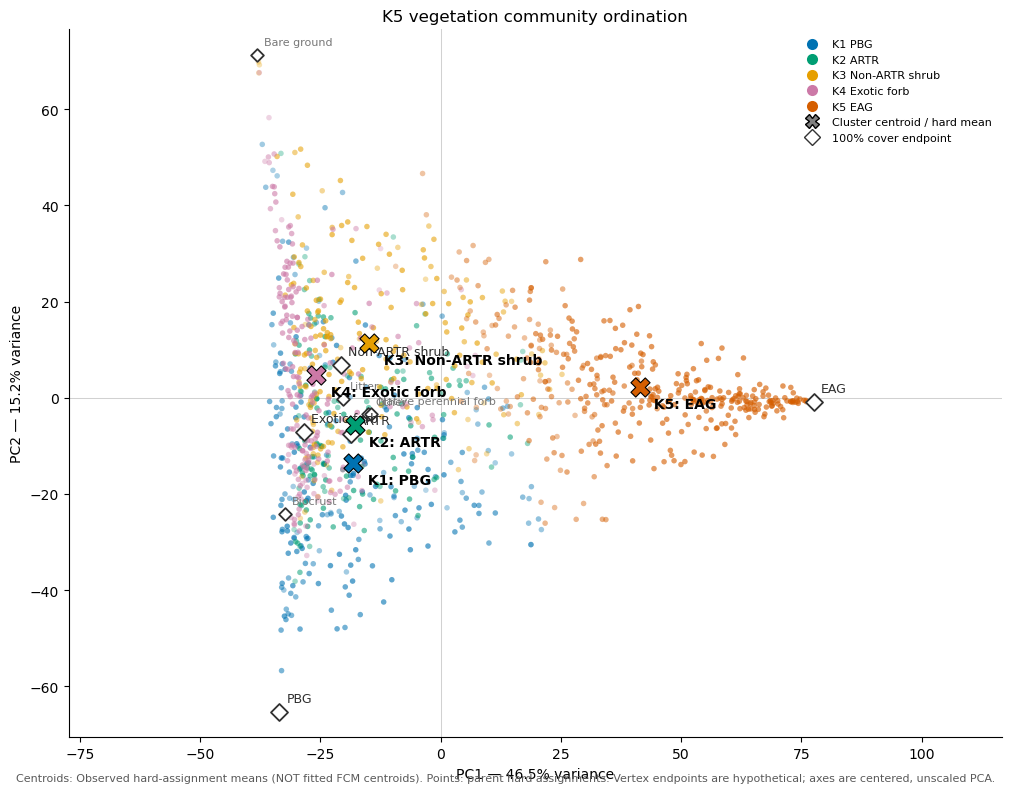

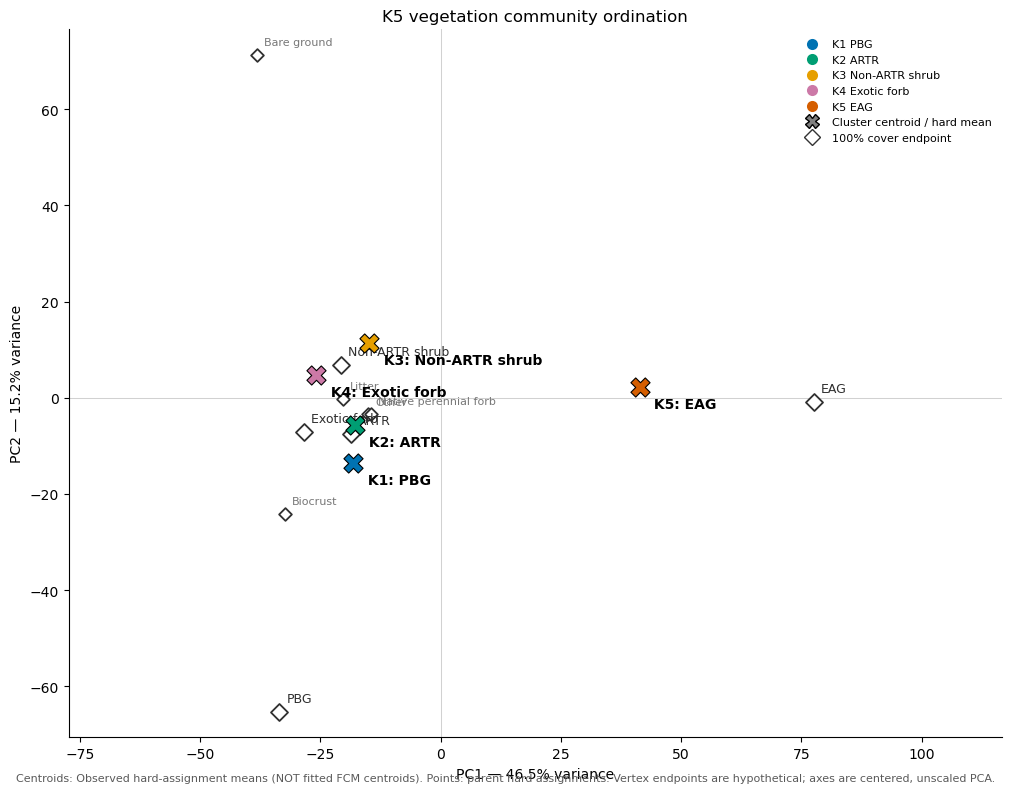

In [17]:
# Common plotting utility: two different layers of evidence, same fitted ordination.
def ordination_plot(include_points=True, include_vertices=True, annotate_vertices=True):
    fig, ax = plt.subplots(figsize=(10,7.8), constrained_layout=True)
    if include_points:
        plot_data = dat
        if MAX_PLOTTED_POINTS is not None and len(dat)>MAX_PLOTTED_POINTS:
            # Thinning for display only; the PCA and centroids still use ALL observations.
            plot_data = dat.sample(MAX_PLOTTED_POINTS,random_state=RANDOM_SEED)
        for k in range(1,6):
            s=plot_data.loc[plot_data["parent_cluster_k5"]==k]
            if len(s)==0: continue
            if USE_MEMBERSHIP_ALPHA and "max_membership_k5" in s:
                confidence=pd.to_numeric(s["max_membership_k5"],errors="coerce").fillna(.4).clip(0,1)
                from matplotlib.colors import to_rgba
                colors=np.array([to_rgba(CLUSTER_COLORS[k],alpha=.14+.50*v) for v in confidence])
            else:
                colors=CLUSTER_COLORS[k]
            ax.scatter(s.PC1,s.PC2,s=POINT_SIZE,c=colors,edgecolors="none",
                       rasterized=True,zorder=2)
    if include_vertices:
        for _,v in vertices.iterrows():
            x,y=v.PC1,v.PC2
            is_main = v["component"] in ["ARTR_FG","SHRUB_FG","PBG_FG","EAG_FG","EF_FG"]
            ax.scatter([x],[y],marker="D",s=75 if is_main else 42,
                       facecolors="white",edgecolors="#303030",
                       linewidths=1.3,zorder=6)
            if annotate_vertices:
                ax.annotate(v["label"],(x,y),xytext=(5,7),textcoords="offset points",
                            fontsize=9 if is_main else 8,
                            color="#2e2e2e" if is_main else "#777777",zorder=7)
    for k,c in centroids.iterrows():
        ax.scatter(c.PC1,c.PC2,s=190,marker="X",c=CLUSTER_COLORS[k],
                   edgecolors="black",linewidths=.8,zorder=8)
        ax.annotate(f" K{k}: {CLUSTER_LABELS[k]}",(c.PC1,c.PC2),
                    xytext=(7,-15),textcoords="offset points",fontsize=10,
                    weight="semibold",zorder=9)
    ax.axhline(0,color=".82",lw=.75,zorder=0)
    ax.axvline(0,color=".82",lw=.75,zorder=0)
    ax.set(xlabel=f"PC1 — {EV[0]:.1%} variance",ylabel=f"PC2 — {EV[1]:.1%} variance",
           title="K5 vegetation community ordination")
    ax.set_aspect("equal",adjustable="datalim") # consistent data-unit scale for geometry
    handles=[Line2D([0],[0],marker="o",color="none",markerfacecolor=CLUSTER_COLORS[k],
                    markeredgecolor="none",markersize=8,label=f"K{k} {CLUSTER_LABELS[k]}")
             for k in range(1,6)]
    handles += [Line2D([0],[0],marker="X",color="none",markerfacecolor="gray",
                       markeredgecolor="black",markersize=10,label="Cluster centroid / hard mean")]
    if include_vertices:
        handles += [Line2D([0],[0],marker="D",color="none",markerfacecolor="white",
                           markeredgecolor="#333333",markersize=8,label="100% cover endpoint")]
    ax.legend(handles=handles,loc="best",frameon=False,fontsize=8)
    fig.text(.01,.005,f"Centroids: {centroid_source}. Points: parent hard assignments. "
             f"Vertex endpoints are hypothetical; axes are centered, unscaled PCA.",fontsize=8,color=".35")
    return fig,ax

fig1,ax1 = ordination_plot(include_points=True,include_vertices=SHOW_ALL_VERTICES)
plt.show()
fig2,ax2 = ordination_plot(include_points=False,include_vertices=True)
plt.show()


## Quantitative checks

The first two PCs need not resolve all five clusters. Compare the 2D distances of the five centroids against distances in the full 10D cover space. Ratios near zero indicate that a pair's separation is nearly invisible in the figure. Note that PCA is descriptive: these measurements are **not** independent evidence validating the K5 clustering fitted to these same observations.


In [18]:
from itertools import combinations
rows=[]
for a,b in combinations(range(1,6),2):
    full=np.linalg.norm(centroid_cover.loc[a].to_numpy()-centroid_cover.loc[b].to_numpy())
    planar=np.linalg.norm(centroids.loc[a,["PC1","PC2"]].to_numpy(dtype=float)
                          -centroids.loc[b,["PC1","PC2"]].to_numpy(dtype=float))
    rows.append({"cluster_a":a,"cluster_b":b,"distance_10D":full,
                 "distance_2D":planar,"distance_retained":planar/full if full>0 else np.nan})
diagnostics=pd.DataFrame(rows)
display(diagnostics.round(3))
print("2D total variance retained:",round(100*sum(EV[:2]),2),"%")
print("Lowest 2D centroid-pair distance retention:",diagnostics.distance_retained.min())


,cluster_a,cluster_b,distance_10D,distance_2D,distance_retained
0,1,2,38.854,7.979,0.205
1,1,3,41.949,25.233,0.602
2,1,4,44.671,19.909,0.446
3,1,5,64.907,61.683,0.950
4,2,3,36.527,17.299,0.474
5,2,4,42.016,13.120,0.312
6,2,5,64.732,59.761,0.923
7,3,4,43.120,12.798,0.297
8,3,5,61.614,56.951,0.924
9,4,5,71.659,67.231,0.938


2D total variance retained: 61.71 %
Lowest 2D centroid-pair distance retention: 0.20536775648632932


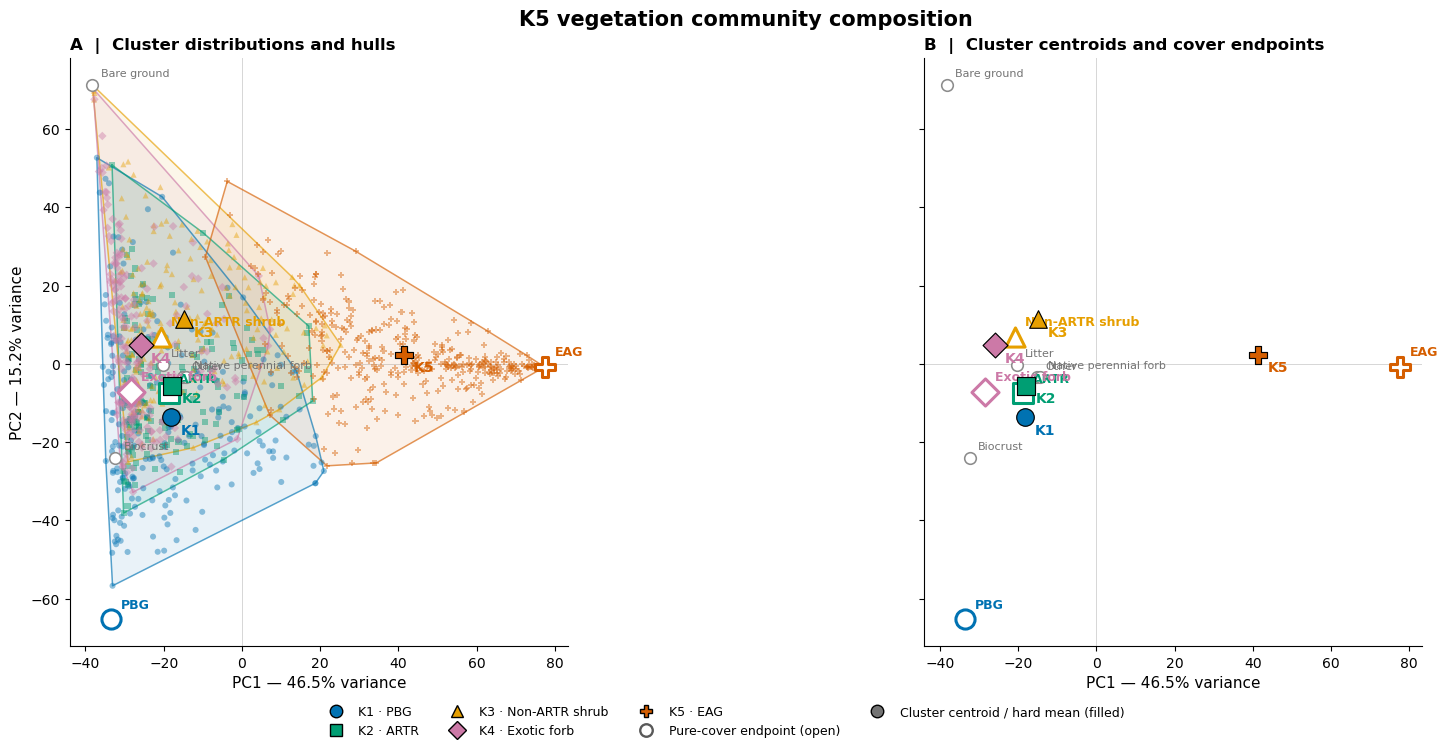

In [19]:

from scipy.spatial import ConvexHull, QhullError
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# K5 PCA — MATCHED SYMBOLS, COVER VERTICES, AND CLUSTER HULLS
# ============================================================

# Match each cluster to its defining functional-group endpoint
CLUSTER_FG = {
    1: "PBG_FG",
    2: "ARTR_FG",
    3: "SHRUB_FG",
    4: "EF_FG",
    5: "EAG_FG",
}

# Consistent marker shapes across observations, centroids,
# and corresponding pure-cover endpoints
CLUSTER_MARKERS = {
    1: "o",   # PBG
    2: "s",   # ARTR
    3: "^",   # Non-ARTR shrub
    4: "D",   # Exotic forb
    5: "P",   # EAG
}

# ------------------------------------------------------------
# Appearance controls
# ------------------------------------------------------------

HULL_COVERAGE = 1.00
# 1.00 = full convex hull
# 0.95 = descriptive hull after radial trimming

HULL_ALPHA = 0.085
POINT_ALPHA = 0.43
POINT_SIZE = 19

CENTROID_SIZE = 160
VERTEX_SIZE = 190
LINE_WIDTH = 1.6

# ------------------------------------------------------------
# Convex hull utility
# ------------------------------------------------------------

def get_cluster_hull(points, coverage=1.0):
    """
    Compute a convex hull in projected PCA space.

    For coverage < 1, remove observations with the largest
    Euclidean distances from the coordinate-wise median.

    Trimmed hulls are descriptive, not statistical
    confidence or probability regions.
    """
    points = np.asarray(points, dtype=float)
    points = points[np.isfinite(points).all(axis=1)]

    if not 0 < coverage <= 1:
        raise ValueError("coverage must be in (0, 1].")

    if len(points) < 3:
        return None

    if coverage < 1:
        center = np.median(points, axis=0)
        distance = np.linalg.norm(points - center, axis=1)
        threshold = np.quantile(distance, coverage)
        points = points[distance <= threshold]

    if len(points) < 3:
        return None

    if np.linalg.matrix_rank(
        points - points.mean(axis=0)
    ) < 2:
        return None

    try:
        hull = ConvexHull(points)
        return points[hull.vertices]
    except QhullError:
        return None


# ============================================================
# TWO-PANEL ORDINATION
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7.4),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for panel, ax in enumerate(axes):

    show_points = panel == 0

    # --------------------------------------------------------
    # Cluster observations and convex hulls
    # --------------------------------------------------------

    for k in range(1, 6):

        subset = dat.loc[
            dat["parent_cluster_k5"] == k
        ]

        xy = subset[["PC1", "PC2"]].to_numpy(
            dtype=float
        )

        color = CLUSTER_COLORS[k]
        marker = CLUSTER_MARKERS[k]

        if show_points and len(xy) > 0:

            hull_xy = get_cluster_hull(
                xy,
                coverage=HULL_COVERAGE
            )

            if hull_xy is not None:

                ax.add_patch(
                    Polygon(
                        hull_xy,
                        closed=True,
                        facecolor=color,
                        edgecolor="none",
                        alpha=HULL_ALPHA,
                        zorder=1
                    )
                )

                closed_hull = np.vstack([
                    hull_xy,
                    hull_xy[0]
                ])

                ax.plot(
                    closed_hull[:, 0],
                    closed_hull[:, 1],
                    color=color,
                    linewidth=1.1,
                    alpha=0.65,
                    zorder=2
                )

            ax.scatter(
                xy[:, 0],
                xy[:, 1],
                s=POINT_SIZE,
                marker=marker,
                color=color,
                alpha=POINT_ALPHA,
                edgecolors="none",
                rasterized=True,
                zorder=3
            )

    # --------------------------------------------------------
    # Non-focal functional-group endpoints
    # --------------------------------------------------------

    for _, v in vertices.iterrows():

        fg = v["component"]

        if fg in CLUSTER_FG.values():
            continue

        ax.scatter(
            v["PC1"],
            v["PC2"],
            marker="o",
            s=70,
            facecolors="white",
            edgecolors="0.55",
            linewidths=1.15,
            zorder=7
        )

        ax.annotate(
            v["label"],
            (v["PC1"], v["PC2"]),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=8,
            color="0.45",
            zorder=8
        )

    # --------------------------------------------------------
    # Matched cluster centroids and pure-cover endpoints
    # --------------------------------------------------------

    for k in range(1, 6):

        fg = CLUSTER_FG[k]

        v = vertices.loc[
            vertices["component"] == fg
        ].iloc[0]

        c = centroids.loc[k]

        color = CLUSTER_COLORS[k]
        marker = CLUSTER_MARKERS[k]

        # Pure-cover endpoint: open, colored marker
        ax.scatter(
            v["PC1"],
            v["PC2"],
            marker=marker,
            s=VERTEX_SIZE,
            facecolors="white",
            edgecolors=color,
            linewidths=2.2,
            zorder=10
        )

        ax.annotate(
            CLUSTER_LABELS[k],
            (v["PC1"], v["PC2"]),
            xytext=(7, 8),
            textcoords="offset points",
            fontsize=9,
            weight="semibold",
            color=color,
            zorder=11
        )

        # Cluster centroid: filled, matching marker
        ax.scatter(
            c["PC1"],
            c["PC2"],
            marker=marker,
            s=CENTROID_SIZE,
            color=color,
            edgecolors="black",
            linewidths=0.85,
            zorder=12
        )

        ax.annotate(
            f"K{k}",
            (c["PC1"], c["PC2"]),
            xytext=(7, -12),
            textcoords="offset points",
            fontsize=10,
            weight="bold",
            color=color,
            zorder=13
        )

    # --------------------------------------------------------
    # Axes and panel styling
    # --------------------------------------------------------

    ax.axhline(
        0,
        color="0.84",
        linewidth=0.7,
        zorder=0
    )

    ax.axvline(
        0,
        color="0.84",
        linewidth=0.7,
        zorder=0
    )

    ax.set_xlabel(
        f"PC1 — {EV[0]:.1%} variance",
        fontsize=11
    )

    # CORRECTED: compatible with sharex=True, sharey=True
    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.set_title(
        "A  |  Cluster distributions and hulls"
        if show_points else
        "B  |  Cluster centroids and cover endpoints",
        fontsize=12,
        loc="left",
        weight="semibold"
    )

axes[0].set_ylabel(
    f"PC2 — {EV[1]:.1%} variance",
    fontsize=11
)

# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------

handles = []

for k in range(1, 6):

    handles.append(
        Line2D(
            [0], [0],
            marker=CLUSTER_MARKERS[k],
            linestyle="none",
            markerfacecolor=CLUSTER_COLORS[k],
            markeredgecolor="black",
            markersize=9,
            label=f"K{k} · {CLUSTER_LABELS[k]}"
        )
    )

# Explain open vs. filled symbols
handles.extend([
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor="white",
        markeredgecolor="0.35",
        markeredgewidth=1.7,
        markersize=9,
        label="Pure-cover endpoint (open)"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor="0.45",
        markeredgecolor="black",
        markersize=9,
        label="Cluster centroid / hard mean (filled)"
    )
])

fig.legend(
    handles=handles,
    loc="outside lower center",
    ncol=4,
    frameon=False,
    fontsize=9
)

fig.suptitle(
    "K5 vegetation community composition",
    fontsize=15,
    weight="semibold"
)

plt.show()


In [20]:
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    # Re-create plots for export, not from previously displayed/closed figures.
    for name, include_points in [("K5_vegetation_PCA_vertices_plots",True),
                                 ("K5_vegetation_PCA_vertices_centroids",False)]:
        fig,_=ordination_plot(include_points=include_points,include_vertices=True)
        fig.savefig(OUTPUT_DIR/f"{name}.pdf",bbox_inches="tight")
        fig.savefig(OUTPUT_DIR/f"{name}.png",dpi=400,bbox_inches="tight")
        plt.close(fig)
    dat[["parent_cluster_k5","PC1","PC2"]].to_csv(OUTPUT_DIR/"K5_plot_PCA_scores.csv",index=False)
    vertices.to_csv(OUTPUT_DIR/"K5_projected_pure_cover_vertices.csv",index=False)
    centroids.to_csv(OUTPUT_DIR/"K5_projected_centroids.csv")
    diagnostics.to_csv(OUTPUT_DIR/"K5_centroid_projection_diagnostics.csv",index=False)
    loadings.to_csv(OUTPUT_DIR/"K5_PCA_loadings.csv")
    print("Exported to",OUTPUT_DIR)
else:
    print("Inline-only mode; set EXPORT=True to write figures and tables.")


Inline-only mode; set EXPORT=True to write figures and tables.


In [21]:

# ============================================================
# K5 m=1.33 — RECOVER FULL FUZZY MEMBERSHIP MATRIX
# ============================================================

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from scipy.special import softmax
from IPython.display import display

K = 5
M = 1.33
TOLERANCE = 1e-4
SAVE_RESULTS = True

# ------------------------------------------------------------
# 1. Exact correspondence between observation and centroid
#    feature columns, including their order
# ------------------------------------------------------------

FEATURE_MAP = {
    "ARTR_FG":       "ARTR",
    "SHRUB_FG":      "Shrub",
    "PBG_FG":        "PBG",
    "EAG_FG":        "EAG",
    "EF_FG":         "EF",
    "BAREGROUND_FG": "Bare",
    "BIOCRUST_FG":   "Biocrust",
    "LITTER_FG":     "Litter",
    "OTHER_FG":      "Other",
    "NPF_FG":        "NPF"
}

# Uses original and centroid_raw from the preceding cells.
# Re-read the full tables if those variables were modified.
original = pd.read_csv(ASSIGNMENT_PATH, low_memory=False)
centroid_raw = pd.read_csv(CENTROID_PATH, low_memory=False)

if centroid_raw.shape[0] != K:
    raise ValueError("Expected exactly five centroid rows.")

ids = pd.to_numeric(
    centroid_raw["cluster_k5"], errors="raise"
).astype(int)

if set(ids) != set(range(1, K + 1)):
    raise ValueError("Cluster IDs must be exactly 1–5.")

centroid_raw = (
    centroid_raw.assign(cluster_k5=ids)
    .sort_values("cluster_k5")
    .reset_index(drop=True)
)

X = original[list(FEATURE_MAP)].apply(
    pd.to_numeric, errors="raise"
).to_numpy(dtype=float)

C = centroid_raw[list(FEATURE_MAP.values())].apply(
    pd.to_numeric, errors="raise"
).to_numpy(dtype=float)

if not (np.isfinite(X).all() and np.isfinite(C).all()):
    raise ValueError("Non-finite values in observations or centroids.")

# ------------------------------------------------------------
# 2. Reconstruct membership using fixed FCM centroids
# ------------------------------------------------------------

D = cdist(X, C, metric="euclidean")

power = 2.0 / (M - 1.0)
U = np.zeros_like(D)

zero_rows = np.any(D == 0, axis=1)

for i in np.flatnonzero(zero_rows):
    matched = D[i] == 0
    U[i, matched] = 1.0 / matched.sum()

nonzero = ~zero_rows

U[nonzero] = softmax(
    -power * np.log(D[nonzero]),
    axis=1
)

assert np.allclose(U.sum(axis=1), 1, atol=1e-10)
assert np.isfinite(U).all()

# ------------------------------------------------------------
# 3. Validate against original saved memberships
# ------------------------------------------------------------

sorted_U = np.sort(U, axis=1)

recovered_max = sorted_U[:, -1]
recovered_second = sorted_U[:, -2]
recovered_margin = recovered_max - recovered_second
recovered_class = np.argmax(U, axis=1) + 1

checks = {
    "max_membership_k5": recovered_max,
    "second_membership_k5": recovered_second,
    "membership_margin_k5": recovered_margin
}

print("K5 MEMBERSHIP RECOVERY")
print("=" * 65)

validated = True

for col, calculated in checks.items():

    if col not in original.columns:
        raise ValueError(
            f"Missing original validation column: {col}"
        )

    stored = pd.to_numeric(
        original[col], errors="raise"
    ).to_numpy(dtype=float)

    error = np.abs(calculated - stored)

    print(
        f"{col:28s} "
        f"MAE = {error.mean():.8f}  "
        f"Max = {error.max():.8f}"
    )

    if not np.isfinite(error).all() or error.max() > TOLERANCE:
        validated = False

stored_class = pd.to_numeric(
    original["parent_cluster_k5"], errors="raise"
).to_numpy(dtype=int)

agreement = (recovered_class == stored_class).mean()

print(f"\nHard-class agreement: {agreement:.2%}")

if agreement < 1:
    validated = False

if not validated:
    raise ValueError(
        "The reconstructed memberships do not reproduce "
        "the original K5 solution. Check feature scaling, "
        "the original distance metric, and whether these "
        "are the fitted FCM centroids."
    )

print("\nPASS — Membership reconstruction validated.")

# ------------------------------------------------------------
# 4. Store all five memberships
# ------------------------------------------------------------

membership_cols = [
    "membership_K1_PBG",
    "membership_K2_ARTR",
    "membership_K3_SHRUB",
    "membership_K4_EF",
    "membership_K5_EAG"
]

membership_df = pd.DataFrame(
    U,
    columns=membership_cols,
    index=original.index
)

recovered = pd.concat(
    [original, membership_df],
    axis=1
)

recovered["membership_entropy_K5"] = (
    -np.sum(
        np.where(
            U > 0,
            U * np.log(np.maximum(U, 1e-300)),
            0.0
        ),
        axis=1
    ) / np.log(K)
)

recovered["recovered_max_membership"] = recovered_max
recovered["recovered_margin"] = recovered_margin

# ------------------------------------------------------------
# 5. Export validated dataset
# ------------------------------------------------------------

if SAVE_RESULTS:
    output_path = (
        ASSIGNMENT_PATH.parent /
        "NCA_FCM_K5_m1p33_full_memberships.csv"
    )

    recovered.to_csv(output_path, index=False)
    print("\nSaved:", output_path)

display(
    recovered[
        ["parent_cluster_k5", *membership_cols,
         "membership_entropy_K5"]
    ].head(10).round(4)
)

print(f"\nRecovered membership matrix: {U.shape}")
print(
    "Mean normalized entropy:",
    round(recovered["membership_entropy_K5"].mean(), 4)
)


NameError: name 'ASSIGNMENT_PATH' is not defined

In [22]:

# ============================================================
# DIAGNOSE K5 MEMBERSHIP RECONSTRUCTION FAILURE
# ============================================================

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from scipy.special import softmax
from IPython.display import display

stored_max = original["max_membership_k5"].to_numpy(float)
stored_second = original["second_membership_k5"].to_numpy(float)
stored_margin = original["membership_margin_k5"].to_numpy(float)
stored_class = original["parent_cluster_k5"].to_numpy(int)

def evaluate_reconstruction(X_test, C_test, m=1.33):
    D = cdist(X_test, C_test)
    U_test = np.zeros_like(D)

    exact = (D == 0).any(axis=1)

    for i in np.flatnonzero(exact):
        matches = D[i] == 0
        U_test[i, matches] = 1 / matches.sum()

    valid = ~exact
    U_test[valid] = softmax(
        -2 / (m - 1) * np.log(D[valid]),
        axis=1
    )

    ordered = np.sort(U_test, axis=1)
    maximum = ordered[:, -1]
    second = ordered[:, -2]
    margin = maximum - second
    predicted = U_test.argmax(axis=1) + 1

    return U_test, {
        "max_MAE": np.mean(np.abs(maximum - stored_max)),
        "max_error": np.max(np.abs(maximum - stored_max)),
        "second_MAE": np.mean(np.abs(second - stored_second)),
        "margin_MAE": np.mean(np.abs(margin - stored_margin)),
        "class_agreement": np.mean(predicted == stored_class),
        "within_1e-4": np.mean(
            np.abs(maximum - stored_max) <= 1e-4
        )
    }

# Compare raw cover, standardized cover, and proportion cover.
# These are sensitivity tests, not alternate accepted solutions.

scale = X.std(axis=0)
if (scale <= 0).any():
    raise ValueError("One or more cover features have zero variance.")

tests = {
    "Raw percentage cover": (X, C),
    "Proportions (X/100)": (X / 100, C / 100),
    "Standardized by plot SD": (X / scale, C / scale),
}

results = {}

for name, (xx, cc) in tests.items():
    _, metrics = evaluate_reconstruction(xx, cc)
    results[name] = metrics

print("RECONSTRUCTION COMPARISON")
display(pd.DataFrame(results).T.round(6))

# Detailed inspection of original raw-cover reconstruction
U_raw, _ = evaluate_reconstruction(X, C)
u_sorted = np.sort(U_raw, axis=1)

comparison = pd.DataFrame({
    "cluster": stored_class,
    "stored_max": stored_max,
    "recovered_max": u_sorted[:, -1],
    "stored_second": stored_second,
    "recovered_second": u_sorted[:, -2],
    "stored_margin": stored_margin,
    "recovered_margin": u_sorted[:, -1] - u_sorted[:, -2],
    "recovered_cluster": U_raw.argmax(axis=1) + 1
})

comparison["abs_error"] = np.abs(
    comparison["stored_max"] - comparison["recovered_max"]
)

print("\nTEN LARGEST DISCREPANCIES")
display(
    comparison.nlargest(10, "abs_error").round(5)
)

print("\nERROR BY ORIGINAL CLUSTER")
display(
    comparison.groupby("cluster")["abs_error"]
    .agg(["count", "mean", "median", "max"])
    .round(6)
)

print("\nCENTROID COVER TOTALS")
print(C.sum(axis=1).round(4))


NameError: name 'original' is not defined

In [23]:

# ============================================================
# K5 m=1.33 — LOAD ORIGINAL FUZZY MEMBERSHIPS
# No refitting or reconstruction required
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

BASE = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33"
)

ASSIGNMENT_PATH = (
    BASE / "Derived" /
    "NCA_FCM_K5_m1p33_parent_assignments.csv"
)

MODEL_PATH = (
    BASE / "Derived" /
    "NCA_FCM_K5_m1p33_model.npz"
)

# 1. Load original assignments
recovered = pd.read_csv(ASSIGNMENT_PATH, low_memory=False)

source_cols = [
    f"membership_k5_{k}" for k in range(1, 6)
]

missing = set(source_cols) - set(recovered.columns)
if missing:
    raise ValueError(f"Missing membership columns: {missing}")

U = recovered[source_cols].to_numpy(dtype=float)

# 2. Verify original membership properties
assert U.shape == (len(recovered), 5)
assert np.isfinite(U).all()
assert np.all((U >= 0) & (U <= 1))
assert np.allclose(U.sum(axis=1), 1, atol=1e-8)

sorted_U = np.sort(U, axis=1)

checks = {
    "max_membership_k5": sorted_U[:, -1],
    "second_membership_k5": sorted_U[:, -2],
    "membership_margin_k5": sorted_U[:, -1] - sorted_U[:, -2]
}

print("ORIGINAL K5 MEMBERSHIP VALIDATION")
print("=" * 55)

for col, calculated in checks.items():
    stored = recovered[col].to_numpy(float)
    error = np.abs(stored - calculated)
    print(f"{col}: maximum error = {error.max():.10f}")
    assert np.allclose(stored, calculated, atol=1e-8)

hard = U.argmax(axis=1) + 1
stored_hard = recovered["parent_cluster_k5"].to_numpy(int)

agreement = np.mean(hard == stored_hard)
print(f"Hard-label agreement: {agreement:.2%}")
assert np.array_equal(hard, stored_hard)

# 3. Optional confirmation against saved model checkpoint
if MODEL_PATH.exists():
    with np.load(MODEL_PATH, allow_pickle=True) as model:
        U_checkpoint = model["memberships"]
        assert U_checkpoint.shape == U.shape
        assert np.allclose(U, U_checkpoint, atol=1e-8)
        print("Original NPZ checkpoint: MATCH")

# 4. Add interpretable column aliases
membership_cols = [
    "membership_K1_PBG",
    "membership_K2_ARTR",
    "membership_K3_SHRUB",
    "membership_K4_EF",
    "membership_K5_EAG"
]

for old, new in zip(source_cols, membership_cols):
    recovered[new] = recovered[old]

# Normalized membership entropy
recovered["membership_entropy_K5"] = (
    -np.sum(
        U * np.log(np.maximum(U, 1e-300)),
        axis=1
    ) / np.log(5)
)

# 5. Summary
print(f"\nObservations: {len(recovered):,}")
print(f"Membership matrix: {U.shape}")
print(
    f"Mean normalized entropy: "
    f"{recovered['membership_entropy_K5'].mean():.4f}"
)

display(
    recovered[
        ["parent_cluster_k5", *membership_cols,
         "membership_entropy_K5"]
    ].head(10).round(4)
)

print("\nSUCCESS: Original K5 memberships loaded.")


ORIGINAL K5 MEMBERSHIP VALIDATION
max_membership_k5: maximum error = 0.0000000000
second_membership_k5: maximum error = 0.0000000000
membership_margin_k5: maximum error = 0.0000000000
Hard-label agreement: 100.00%
Original NPZ checkpoint: MATCH

Observations: 1,171
Membership matrix: (1171, 5)
Mean normalized entropy: 0.3497


C:\Users\scottfordham\AppData\Local\Temp\ipykernel_12660\798741792.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  recovered[new] = recovered[old]
C:\Users\scottfordham\AppData\Local\Temp\ipykernel_12660\798741792.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  recovered[new] = recovered[old]
C:\Users\scottfordham\AppData\Local\Temp\ipykernel_12660\798741792.py:86: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 

,parent_cluster_k5,membership_K1_PBG,membership_K2_ARTR,membership_K3_SHRUB,membership_K4_EF,membership_K5_EAG,membership_entropy_K5
0,3,0.1324,0.0365,0.7944,0.0244,0.0123,0.4449
1,4,0.0157,0.0117,0.0174,0.9491,0.0061,0.1668
2,4,0.0092,0.0073,0.0132,0.9643,0.0061,0.1256
3,5,0.0441,0.3672,0.0588,0.0505,0.4795,0.7302
4,5,0.0007,0.0005,0.0008,0.0002,0.9978,0.0117
5,2,0.0291,0.7916,0.0403,0.1123,0.0267,0.4720
6,5,0.0472,0.0378,0.1021,0.0267,0.7862,0.4888
7,5,0.0046,0.0056,0.0092,0.0031,0.9775,0.0851
8,5,0.0120,0.0225,0.0221,0.0062,0.9371,0.1959
9,3,0.0142,0.0195,0.9405,0.0107,0.0150,0.1905



SUCCESS: Original K5 memberships loaded.


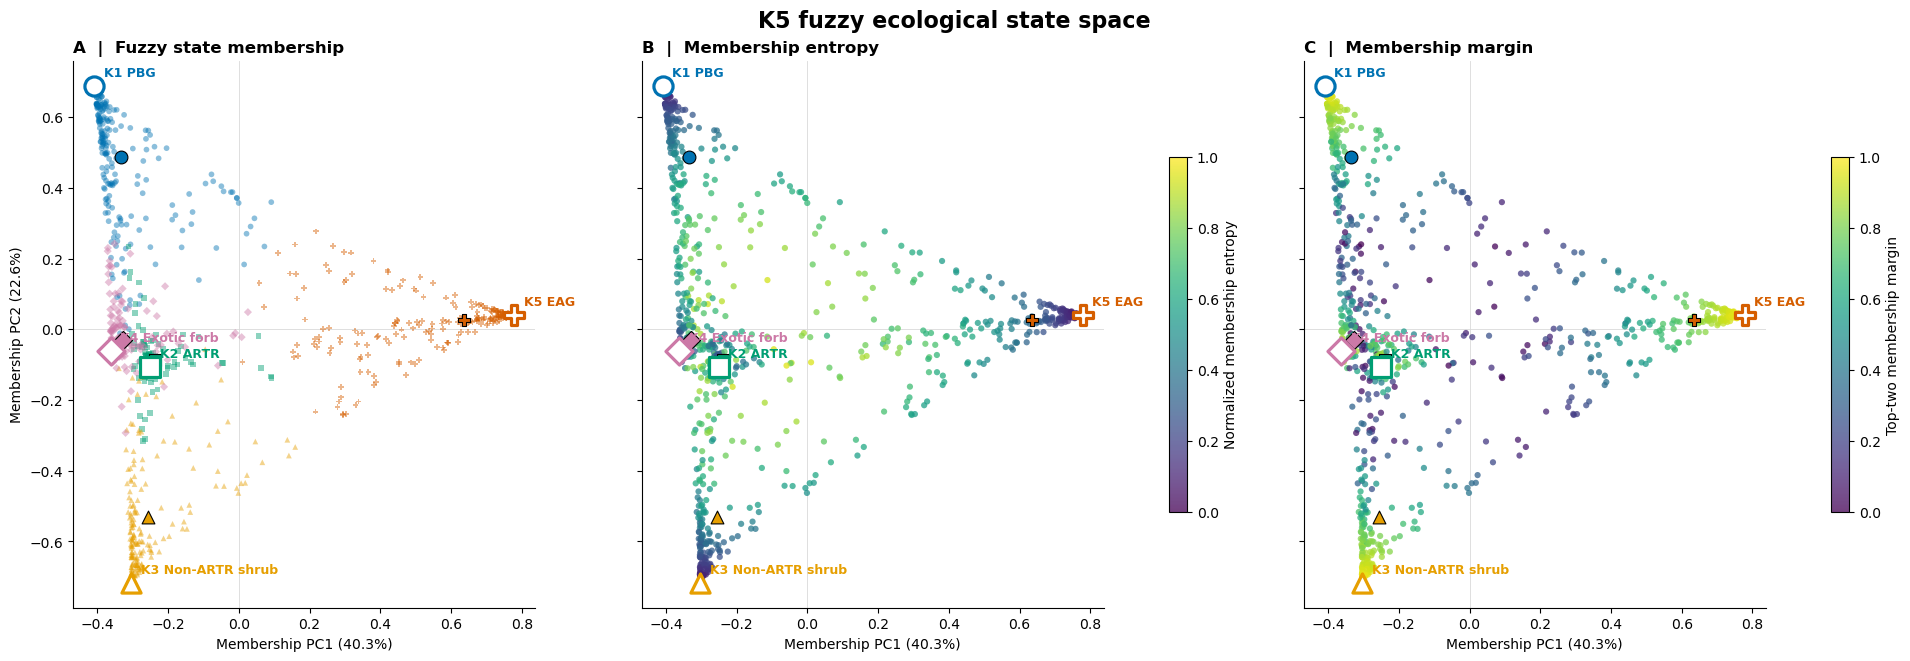

MEMBERSHIP ORDINATION DIAGNOSTICS
PC1: 40.28%
PC2: 22.59%
Combined: 62.87%

Mean entropy: 0.3497
Mean membership margin: 0.7071

PCA loadings:


,PC1,PC2,PC3
membership_K1_PBG,-0.300,0.720,-0.377
membership_K2_ARTR,-0.141,-0.076,-0.026
membership_K3_SHRUB,-0.194,-0.686,-0.427
membership_K4_EF,-0.253,-0.030,0.821
membership_K5_EAG,0.888,0.072,0.009


In [24]:

# ============================================================
# K5 FUZZY MEMBERSHIP SPACE — PCA ORDINATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# 1. Original five-dimensional memberships
# ------------------------------------------------------------

membership_cols = [
    "membership_K1_PBG",
    "membership_K2_ARTR",
    "membership_K3_SHRUB",
    "membership_K4_EF",
    "membership_K5_EAG"
]

U = recovered[membership_cols].to_numpy(dtype=float)
hard = U.argmax(axis=1) + 1

assert np.isfinite(U).all()
assert np.allclose(U.sum(axis=1), 1, atol=1e-8)

cluster_names = {
    1: "PBG",
    2: "ARTR",
    3: "Non-ARTR shrub",
    4: "Exotic forb",
    5: "EAG"
}

colors = {
    1: "#0072B2",
    2: "#009E73",
    3: "#E69F00",
    4: "#CC79A7",
    5: "#D55E00"
}

markers = {
    1: "o",
    2: "s",
    3: "^",
    4: "D",
    5: "P"
}

# ------------------------------------------------------------
# 2. PCA in five-dimensional membership space
# ------------------------------------------------------------

membership_pca = PCA(n_components=4)
membership_pca.fit(U)

XY = membership_pca.transform(U)[:, :2]
explained = membership_pca.explained_variance_ratio_

# Five pure-membership vertices
#
# K1 = [1,0,0,0,0]
# K2 = [0,1,0,0,0], etc.

pure_vertices = np.eye(5)
V = membership_pca.transform(pure_vertices)[:, :2]

# Observed membership-weighted centroids of hard classes
membership_centers = np.array([
    XY[hard == k].mean(axis=0)
    for k in range(1, 6)
])

# ------------------------------------------------------------
# 3. Entropy and membership margin
# ------------------------------------------------------------

entropy = -np.sum(
    U * np.log(np.maximum(U, 1e-300)),
    axis=1
) / np.log(5)

sorted_u = np.sort(U, axis=1)

margin = sorted_u[:, -1] - sorted_u[:, -2]

# ------------------------------------------------------------
# 4. Three-panel figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 6.5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

# Panel A — Hard class and fuzzy distribution
ax = axes[0]

for k in range(1, 6):
    mask = hard == k

    ax.scatter(
        XY[mask, 0],
        XY[mask, 1],
        s=17,
        marker=markers[k],
        c=colors[k],
        alpha=0.45,
        edgecolors="none",
        rasterized=True,
        zorder=2
    )

# Panel B — Membership entropy
sc_entropy = axes[1].scatter(
    XY[:, 0],
    XY[:, 1],
    c=entropy,
    cmap="viridis",
    norm=Normalize(0, 1),
    s=20,
    alpha=0.75,
    edgecolors="none",
    rasterized=True
)

fig.colorbar(
    sc_entropy,
    ax=axes[1],
    shrink=0.65,
    label="Normalized membership entropy"
)

# Panel C — Membership margin
sc_margin = axes[2].scatter(
    XY[:, 0],
    XY[:, 1],
    c=margin,
    cmap="viridis",
    norm=Normalize(0, 1),
    s=20,
    alpha=0.75,
    edgecolors="none",
    rasterized=True
)

fig.colorbar(
    sc_margin,
    ax=axes[2],
    shrink=0.65,
    label="Top-two membership margin"
)

# ------------------------------------------------------------
# 5. Project vertices and cluster centers on every panel
# ------------------------------------------------------------

for ax in axes:

    for k in range(1, 6):

        color = colors[k]
        marker = markers[k]

        # Pure membership vertex: open symbol
        ax.scatter(
            V[k-1, 0],
            V[k-1, 1],
            marker=marker,
            s=190,
            facecolors="white",
            edgecolors=color,
            linewidths=2.3,
            zorder=10
        )

        ax.annotate(
            f"K{k} {cluster_names[k]}",
            V[k-1],
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=9,
            weight="semibold",
            color=color,
            zorder=11
        )

        # Mean membership coordinate of hard-assigned plots
        ax.scatter(
            membership_centers[k-1, 0],
            membership_centers[k-1, 1],
            marker=marker,
            s=85,
            c=color,
            edgecolors="black",
            linewidths=0.8,
            zorder=9
        )

    ax.axhline(0, color="0.85", lw=0.6, zorder=0)
    ax.axvline(0, color="0.85", lw=0.6, zorder=0)

    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel(
        f"Membership PC1 ({explained[0]:.1%})"
    )

axes[0].set_ylabel(
    f"Membership PC2 ({explained[1]:.1%})"
)

axes[0].set_title(
    "A  |  Fuzzy state membership",
    loc="left",
    weight="bold"
)

axes[1].set_title(
    "B  |  Membership entropy",
    loc="left",
    weight="bold"
)

axes[2].set_title(
    "C  |  Membership margin",
    loc="left",
    weight="bold"
)

fig.suptitle(
    "K5 fuzzy ecological state space",
    fontsize=16,
    weight="bold"
)

plt.show()

# ------------------------------------------------------------
# 6. Diagnostics
# ------------------------------------------------------------

print("MEMBERSHIP ORDINATION DIAGNOSTICS")
print("=" * 50)

print(f"PC1: {explained[0]:.2%}")
print(f"PC2: {explained[1]:.2%}")
print(f"Combined: {explained[:2].sum():.2%}")

print(f"\nMean entropy: {entropy.mean():.4f}")
print(f"Mean membership margin: {margin.mean():.4f}")

print("\nPCA loadings:")
display(
    pd.DataFrame(
        membership_pca.components_[:3].T,
        index=membership_cols,
        columns=["PC1", "PC2", "PC3"]
    ).round(3)
)


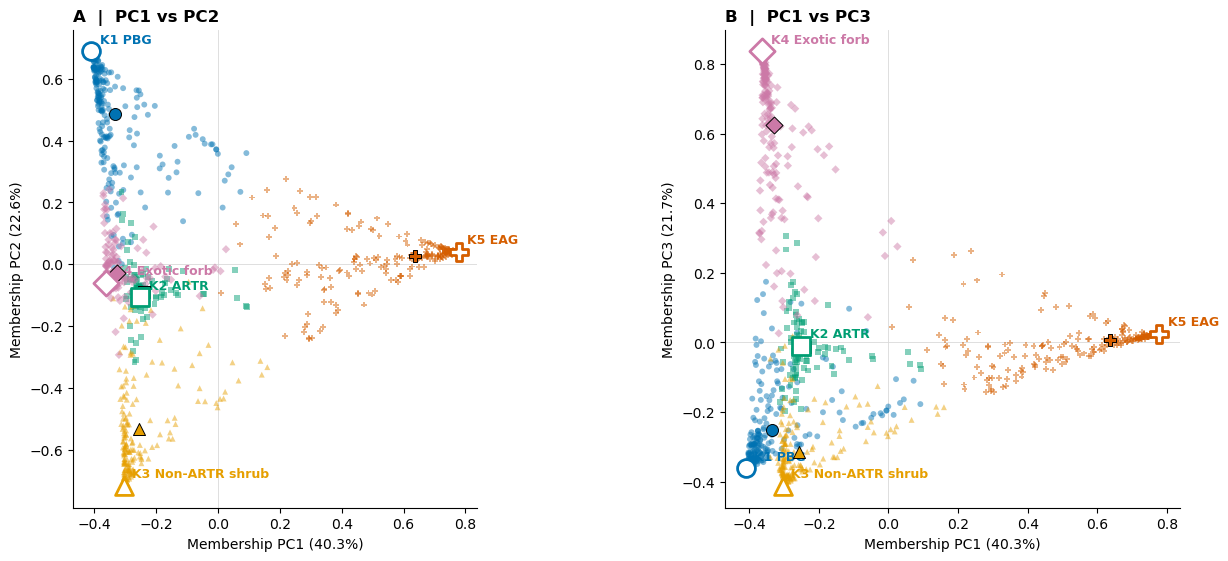

MEMBERSHIP PCA DIAGNOSTICS
PC1: 40.28%
PC2: 22.59%
PC3: 21.71%
PC4: 15.42%

PC1 + PC2: 62.87%
PC1 + PC3: 61.99%
PC1–PC3 total: 84.58%


,PC1,PC2,PC3
membership_K1_PBG,-0.300,0.720,-0.377
membership_K2_ARTR,-0.141,-0.076,-0.026
membership_K3_SHRUB,-0.194,-0.686,-0.427
membership_K4_EF,-0.253,-0.030,0.821
membership_K5_EAG,0.888,0.072,0.009


In [ ]:

# ============================================================
# K5 FUZZY MEMBERSHIP SPACE — PC1/PC2 AND PC1/PC3
# ============================================================

# All four nonzero PCA dimensions, fitted only once
scores = membership_pca.transform(U)
vertices = membership_pca.transform(np.eye(5))

centers = np.vstack([
    scores[hard == k].mean(axis=0)
    for k in range(1, 6)
])

explained = membership_pca.explained_variance_ratio_

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.5, 5.5),
    constrained_layout=True
)

projections = [
    (0, 1, "A  |  PC1 vs PC2"),
    (0, 2, "B  |  PC1 vs PC3")
]

for ax, (xpc, ypc, title) in zip(axes, projections):

    # Observation-level fuzzy memberships
    for k in range(1, 6):
        mask = hard == k

        ax.scatter(
            scores[mask, xpc],
            scores[mask, ypc],
            s=18,
            marker=markers[k],
            color=colors[k],
            alpha=0.48,
            edgecolors="none",
            rasterized=True,
            zorder=2
        )

    # Projected pure-membership vertices
    for k in range(1, 6):
        ax.scatter(
            vertices[k-1, xpc],
            vertices[k-1, ypc],
            marker=markers[k],
            s=165,
            facecolors="white",
            edgecolors=colors[k],
            linewidths=2.0,
            zorder=10
        )

        ax.annotate(
            f"K{k} {cluster_names[k]}",
            (
                vertices[k-1, xpc],
                vertices[k-1, ypc]
            ),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=9,
            weight="semibold",
            color=colors[k]
        )

        # Observed center of hard-assigned observations
        ax.scatter(
            centers[k-1, xpc],
            centers[k-1, ypc],
            marker=markers[k],
            s=75,
            color=colors[k],
            edgecolors="black",
            linewidths=0.7,
            zorder=9
        )

    ax.axhline(0, color="0.85", lw=0.6, zorder=0)
    ax.axvline(0, color="0.85", lw=0.6, zorder=0)

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title, loc="left", weight="bold")

    ax.set_xlabel(
        f"Membership PC{xpc+1} ({explained[xpc]:.1%})"
    )
    ax.set_ylabel(
        f"Membership PC{ypc+1} ({explained[ypc]:.1%})"
    )

plt.show()

print("MEMBERSHIP PCA DIAGNOSTICS")
print("=" * 45)

for i in range(4):
    print(f"PC{i+1}: {explained[i]:.2%}")

print(f"\nPC1 + PC2: {explained[[0, 1]].sum():.2%}")
print(f"PC1 + PC3: {explained[[0, 2]].sum():.2%}")
print(f"PC1–PC3 total: {explained[:3].sum():.2%}")

display(
    pd.DataFrame(
        membership_pca.components_[:3].T,
        index=membership_cols,
        columns=["PC1", "PC2", "PC3"]
    ).round(3)
)


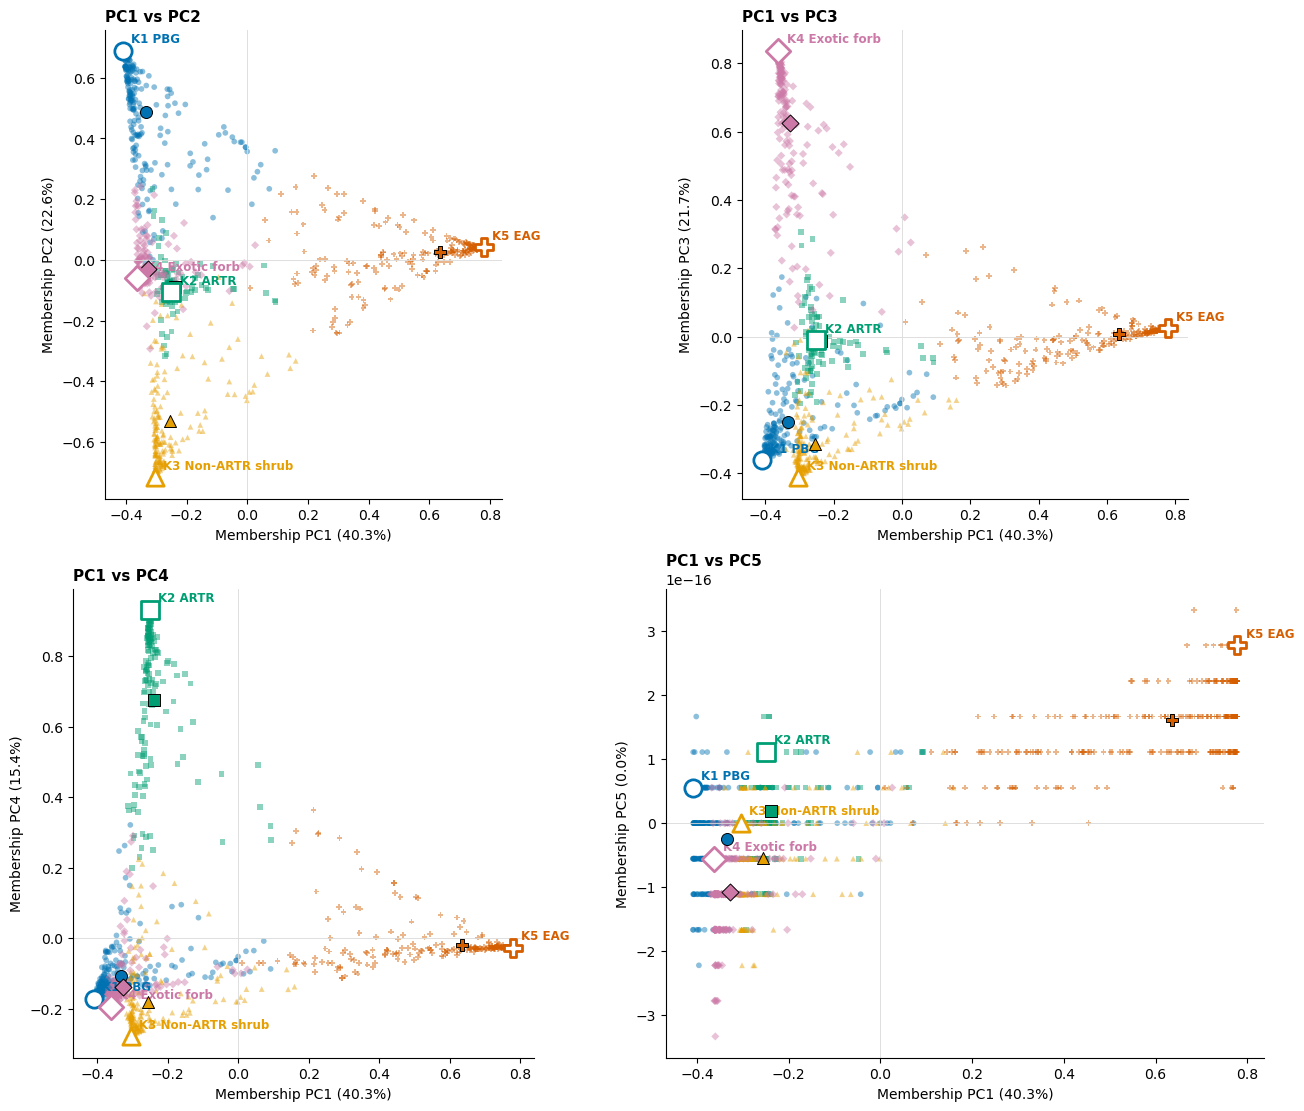

K5 MEMBERSHIP PCA — ALL COMPONENTS
PC1: 40.2769%
PC2: 22.5904%
PC3: 21.7147%
PC4: 15.4180%
PC5: 0.0000%

Cumulative PC1–PC4: 100.0000%


,PC1,PC2,PC3,PC4,PC5
membership_K1_PBG,-0.300,0.720,-0.377,-0.224,0.447
membership_K2_ARTR,-0.141,-0.076,-0.026,0.880,0.447
membership_K3_SHRUB,-0.194,-0.686,-0.427,-0.330,0.447
membership_K4_EF,-0.253,-0.030,0.821,-0.247,0.447
membership_K5_EAG,0.888,0.072,0.009,-0.078,0.447


In [27]:

# ============================================================
# K5 FUZZY MEMBERSHIP SPACE
# PC1 vs PC2, PC3, PC4, PC5
# ============================================================

from sklearn.decomposition import PCA

# Reuse the original five membership variables and styling
# Fit all 5 components to expose the zero-variance fifth axis
pca_all = PCA(n_components=5)
scores_all = pca_all.fit_transform(U)

vertices_all = pca_all.transform(np.eye(5))
explained_all = pca_all.explained_variance_ratio_

centers_all = np.vstack([
    scores_all[hard == k].mean(axis=0)
    for k in range(1, 6)
])

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 11),
    constrained_layout=True
)

for ax, pc_y in zip(axes.flat, [1, 2, 3, 4]):

    # Individual observations
    for k in range(1, 6):
        mask = hard == k

        ax.scatter(
            scores_all[mask, 0],
            scores_all[mask, pc_y],
            s=17,
            marker=markers[k],
            color=colors[k],
            alpha=0.45,
            edgecolors="none",
            rasterized=True,
            zorder=2
        )

    # Pure-membership vertices and observed centers
    for k in range(1, 6):

        ax.scatter(
            vertices_all[k-1, 0],
            vertices_all[k-1, pc_y],
            marker=markers[k],
            s=155,
            facecolors="white",
            edgecolors=colors[k],
            linewidths=2,
            zorder=10
        )

        ax.annotate(
            f"K{k} {cluster_names[k]}",
            (
                vertices_all[k-1, 0],
                vertices_all[k-1, pc_y]
            ),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=8.5,
            weight="semibold",
            color=colors[k]
        )

        ax.scatter(
            centers_all[k-1, 0],
            centers_all[k-1, pc_y],
            marker=markers[k],
            s=75,
            color=colors[k],
            edgecolors="black",
            linewidths=0.7,
            zorder=9
        )

    ax.axhline(0, color="0.85", lw=0.6)
    ax.axvline(0, color="0.85", lw=0.6)

    # Avoid an artificial aspect ratio for zero-variance PC5
    if pc_y != 4:
        ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel(
        f"Membership PC1 ({explained_all[0]:.1%})"
    )
    ax.set_ylabel(
        f"Membership PC{pc_y+1} "
        f"({explained_all[pc_y]:.1%})"
    )

    ax.set_title(
        f"PC1 vs PC{pc_y+1}",
        loc="left",
        fontsize=11,
        weight="bold"
    )

plt.show()

# ------------------------------------------------------------
# Explained variance and membership loadings
# ------------------------------------------------------------

print("K5 MEMBERSHIP PCA — ALL COMPONENTS")
print("=" * 45)

for i, variance in enumerate(explained_all, start=1):
    print(f"PC{i}: {variance:.4%}")

print(
    f"\nCumulative PC1–PC4: "
    f"{explained_all[:4].sum():.4%}"
)

display(
    pd.DataFrame(
        pca_all.components_.T,
        index=membership_cols,
        columns=[f"PC{i}" for i in range(1, 6)]
    ).round(3)
)


NameError: name 'scores_all' is not defined

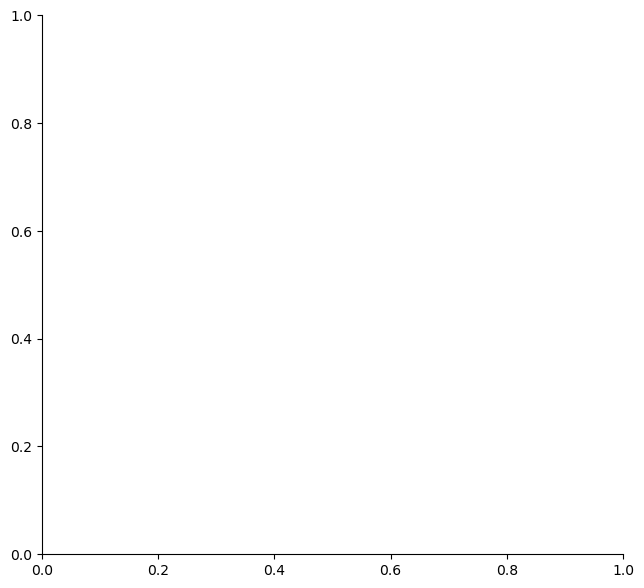

In [26]:

# ============================================================
# K5 FUZZY MEMBERSHIP SPACE — PC2 vs PC3
# ============================================================

xpc, ypc = 1, 2  # Zero-indexed: PC2 and PC3

fig, ax = plt.subplots(figsize=(7.5, 7))

# Individual vegetation plots
for k in range(1, 6):
    mask = hard == k

    ax.scatter(
        scores_all[mask, xpc],
        scores_all[mask, ypc],
        s=18,
        marker=markers[k],
        color=colors[k],
        alpha=0.48,
        edgecolors="none",
        rasterized=True,
        zorder=2
    )

# Pure membership vertices and observed cluster centers
for k in range(1, 6):

    ax.scatter(
        vertices_all[k-1, xpc],
        vertices_all[k-1, ypc],
        marker=markers[k],
        s=165,
        facecolors="white",
        edgecolors=colors[k],
        linewidths=2,
        zorder=10
    )

    ax.annotate(
        f"K{k} {cluster_names[k]}",
        (
            vertices_all[k-1, xpc],
            vertices_all[k-1, ypc]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=9,
        weight="semibold",
        color=colors[k]
    )

    ax.scatter(
        centers_all[k-1, xpc],
        centers_all[k-1, ypc],
        marker=markers[k],
        s=80,
        color=colors[k],
        edgecolors="black",
        linewidths=0.7,
        zorder=9
    )

ax.axhline(0, color="0.85", lw=0.6, zorder=0)
ax.axvline(0, color="0.85", lw=0.6, zorder=0)

ax.set_aspect("equal", adjustable="box")

ax.set_xlabel(
    f"Membership PC2 ({explained_all[1]:.1%})"
)
ax.set_ylabel(
    f"Membership PC3 ({explained_all[2]:.1%})"
)

ax.set_title(
    "K5 fuzzy ecological state space | PC2 vs PC3",
    loc="left",
    fontsize=12,
    weight="bold"
)

fig.tight_layout()
plt.show()


In [ ]:

# ============================================================
# K5 NMDS — vegan monoMDS, visualized in Python
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
import tempfile
import shutil
from pathlib import Path
from scipy.spatial import ConvexHull
from matplotlib.patches import Polygon

# Locate Rscript on Windows
rscript = shutil.which("Rscript")

if rscript is None:
    candidates = sorted(
        Path("C:/Program Files/R").glob("R-*/bin/Rscript.exe"),
        reverse=True
    )
    if not candidates:
        raise FileNotFoundError(
            "Rscript not found. Set rscript to your Rscript.exe path."
        )
    rscript = str(candidates[0])

with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)

    data_path = tmp / "hellinger.csv"
    coords_path = tmp / "nmds_coordinates.csv"
    stress_path = tmp / "stress.txt"
    script_path = tmp / "run_nmds.R"

    pd.DataFrame(X_unique).to_csv(
        data_path, index=False, header=False
    )

    r_code = f'''
    if (!requireNamespace("vegan", quietly=TRUE))
        stop("Install vegan with install.packages('vegan')")

    library(vegan)

    X <- as.matrix(read.csv(
        "{data_path.as_posix()}",
        header=FALSE
    ))

    stopifnot(all(is.finite(X)))

    # Euclidean in Hellinger-transformed space
    D <- dist(X, method="euclidean")

    set.seed(31)

    fit <- metaMDS(
        D,
        k=2,
        engine="monoMDS",
        try=20,
        trymax=50,
        trace=0,
        autotransform=FALSE,
        wascores=FALSE
    )

    write.csv(
        as.data.frame(scores(fit, display="sites")),
        "{coords_path.as_posix()}",
        row.names=FALSE
    )

    writeLines(
        as.character(fit$stress),
        "{stress_path.as_posix()}"
    )
    '''

    script_path.write_text(r_code, encoding="utf-8")

    result = subprocess.run(
        [str(rscript), str(script_path)],
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        raise RuntimeError(
            "R NMDS failed:\n" + result.stderr
        )

    XY_unique = pd.read_csv(coords_path).to_numpy()
    stress = float(stress_path.read_text().strip())

# Keep a distinct ordination table
nmds_data = unique_data.copy()

assert len(XY_unique) == len(nmds_data)
assert np.isfinite(XY_unique).all()

nmds_data["NMDS1"] = XY_unique[:, 0]
nmds_data["NMDS2"] = XY_unique[:, 1]

print(f"Unique observations: {len(nmds_data)}")
print(f"NMDS stress: {stress:.4f}")

# ------------------------------------------------------------
# Plot hard classes and convex hulls
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 8),
    constrained_layout=True
)

for k in range(1, 6):

    sub = nmds_data.loc[
        nmds_data["parent_cluster_k5"] == k
    ]

    xy = sub[["NMDS1", "NMDS2"]].to_numpy()

    color = CLUSTER_COLORS[k]
    marker = CLUSTER_MARKERS[k]

    if len(xy) >= 3 and np.linalg.matrix_rank(
        xy - xy.mean(axis=0)
    ) == 2:

        hull = ConvexHull(xy)
        polygon = xy[hull.vertices]

        ax.add_patch(
            Polygon(
                polygon,
                facecolor=color,
                alpha=0.09,
                edgecolor="none"
            )
        )

        ring = np.vstack([polygon, polygon[0]])
        ax.plot(
            ring[:, 0], ring[:, 1],
            color=color, lw=1, alpha=0.65
        )

    ax.scatter(
        xy[:, 0], xy[:, 1],
        color=color,
        marker=marker,
        s=20,
        alpha=0.45,
        edgecolors="none",
        label=f"K{k} — {CLUSTER_LABELS[k]}",
        rasterized=True
    )

    center = xy.mean(axis=0)

    ax.scatter(
        *center,
        color=color,
        marker=marker,
        s=190,
        edgecolors="black",
        linewidths=1,
        zorder=5
    )

    ax.annotate(
        f"K{k}",
        center,
        xytext=(8, 8),
        textcoords="offset points",
        color=color,
        fontsize=11,
        weight="bold"
    )

ax.set(
    xlabel="NMDS1",
    ylabel="NMDS2",
    title=f"K5 vegetation communities | Hellinger NMDS\n"
          f"Stress = {stress:.3f}; n = {len(nmds_data):,}"
)

ax.set_aspect("equal", adjustable="box")
ax.legend(frameon=False, loc="best")
plt.show()


NameError: name 'X_unique' is not defined

In [ ]:
# ============================================================
# K5 — 3D Hellinger PCA / PCoA-style ordination
# Interactive Plotly figure with optional 3D hull meshes
# ============================================================

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from scipy.spatial import ConvexHull, QhullError
import plotly.graph_objects as go

# ------------------------------------------------------------
# 1. Inputs
# ------------------------------------------------------------

Xh = np.asarray(X_unique, dtype=float)
plot_data = nmds_data.copy()

assert Xh.shape[0] == len(plot_data)
assert np.isfinite(Xh).all()

hard = plot_data["parent_cluster_k5"].to_numpy(dtype=int)

# Plotly marker-symbol mapping
PLOTLY_MARKERS = {
    1: "circle",     # PBG
    2: "square",     # ARTR
    3: "diamond",    # Non-ARTR shrub
    4: "x",          # Exotic forb
    5: "cross"       # EAG
}

SHOW_HULLS = True
POINT_SIZE = 4
POINT_OPACITY = 0.55
CENTROID_SIZE = 11
HULL_OPACITY = 0.10

# ------------------------------------------------------------
# 2. 3D PCA in Hellinger space
# ------------------------------------------------------------

hel_pca_3d = PCA(n_components=3)
XYZ = hel_pca_3d.fit_transform(Xh)

plot_data["PC1_h"] = XYZ[:, 0]
plot_data["PC2_h"] = XYZ[:, 1]
plot_data["PC3_h"] = XYZ[:, 2]

evr = hel_pca_3d.explained_variance_ratio_
print("3D Hellinger PCA")
print(f"PC1: {evr[0]:.2%}")
print(f"PC2: {evr[1]:.2%}")
print(f"PC3: {evr[2]:.2%}")
print(f"Combined (PC1–PC3): {evr[:3].sum():.2%}")

# ------------------------------------------------------------
# 3. Cluster centroids in 3D PCA space
# ------------------------------------------------------------

centroids_3d = (
    plot_data
    .groupby("parent_cluster_k5")[["PC1_h", "PC2_h", "PC3_h"]]
    .mean()
    .reindex(range(1, 6))
)

# ------------------------------------------------------------
# 4. Build interactive 3D figure
# ------------------------------------------------------------

fig = go.Figure()

# Hull meshes first so points draw on top
if SHOW_HULLS:
    for k in range(1, 6):
        sub = plot_data.loc[plot_data["parent_cluster_k5"] == k]
        pts = sub[["PC1_h", "PC2_h", "PC3_h"]].to_numpy(dtype=float)

        # Need at least 4 non-coplanar points for a 3D hull
        if len(pts) >= 4:
            try:
                hull = ConvexHull(pts)
                simplices = hull.simplices

                fig.add_trace(
                    go.Mesh3d(
                        x=pts[:, 0],
                        y=pts[:, 1],
                        z=pts[:, 2],
                        i=simplices[:, 0],
                        j=simplices[:, 1],
                        k=simplices[:, 2],
                        color=CLUSTER_COLORS[k],
                        opacity=HULL_OPACITY,
                        name=f"K{k} hull",
                        hoverinfo="skip",
                        showlegend=False
                    )
                )
            except QhullError:
                pass

# Points by hard class
for k in range(1, 6):
    sub = plot_data.loc[plot_data["parent_cluster_k5"] == k]

    fig.add_trace(
        go.Scatter3d(
            x=sub["PC1_h"],
            y=sub["PC2_h"],
            z=sub["PC3_h"],
            mode="markers",
            name=f"K{k} — {CLUSTER_LABELS[k]}",
            marker=dict(
                size=POINT_SIZE,
                color=CLUSTER_COLORS[k],
                symbol=PLOTLY_MARKERS[k],
                opacity=POINT_OPACITY
            ),
            customdata=np.c_[
                sub["parent_cluster_k5"].to_numpy(),
                sub.index.to_numpy()
            ],
            hovertemplate=(
                "Cluster: K%{customdata[0]}<br>"
                "Row index: %{customdata[1]}<br>"
                "PC1: %{x:.3f}<br>"
                "PC2: %{y:.3f}<br>"
                "PC3: %{z:.3f}<extra></extra>"
            )
        )
    )

# Centroids
for k in range(1, 6):
    c = centroids_3d.loc[k]

    fig.add_trace(
        go.Scatter3d(
            x=[c["PC1_h"]],
            y=[c["PC2_h"]],
            z=[c["PC3_h"]],
            mode="markers+text",
            name=f"K{k} centroid",
            marker=dict(
                size=CENTROID_SIZE,
                color=CLUSTER_COLORS[k],
                symbol="circle",
                line=dict(color="black", width=3)
            ),
            text=[f"K{k}"],
            textposition="top center",
            showlegend=False,
            hovertemplate=(
                f"K{k}: {CLUSTER_LABELS[k]}<br>"
                "Centroid<br>"
                "PC1: %{x:.3f}<br>"
                "PC2: %{y:.3f}<br>"
                "PC3: %{z:.3f}<extra></extra>"
            )
        )
    )

fig.update_layout(
    title=(
        "K5 vegetation communities — 3D Hellinger PCA"
        f"<br><sup>Variance retained: "
        f"PC1={evr[0]:.1%}, PC2={evr[1]:.1%}, PC3={evr[2]:.1%}; "
        f"Combined={evr[:3].sum():.1%}</sup>"
    ),
    scene=dict(
        xaxis_title=f"PC1 ({evr[0]:.1%})",
        yaxis_title=f"PC2 ({evr[1]:.1%})",
        zaxis_title=f"PC3 ({evr[2]:.1%})",
        aspectmode="data"
    ),
    width=1000,
    height=800,
    legend=dict(
        title="Hard-assigned K5 class",
        itemsizing="constant"
    ),
    margin=dict(l=0, r=0, b=0, t=70)
)

fig.show()

# ------------------------------------------------------------
# 5. Optional numeric output
# ------------------------------------------------------------

display(centroids_3d.round(4))

loadings_3d = pd.DataFrame(
    hel_pca_3d.components_.T,
    index=[
        "ARTR_FG", "SHRUB_FG", "PBG_FG", "EAG_FG", "EF_FG",
        "BAREGROUND_FG", "BIOCRUST_FG", "LITTER_FG", "OTHER_FG", "NPF_FG"
    ],
    columns=["PC1", "PC2", "PC3"]
)

print("\n3D PCA loadings:")
display(loadings_3d.round(3))

NameError: name 'X_unique' is not defined

In [ ]:

# ============================================================
# K5 — 3D HELLINGER PCA WITH FUZZY MEMBERSHIP ENTROPY
# ============================================================

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy.spatial import ConvexHull, QhullError

# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

SHOW_HULLS = False  # Enable for class-colored 3D hulls
POINT_SIZE = 4
POINT_OPACITY = 0.85
HULL_OPACITY = 0.06

CLUSTER_MARKERS_3D = {
    1: "circle",
    2: "square",
    3: "diamond",
    4: "x",
    5: "cross"
}

MEMBERSHIP_COLS = [
    "membership_K1_PBG",
    "membership_K2_ARTR",
    "membership_K3_SHRUB",
    "membership_K4_EF",
    "membership_K5_EAG"
]

# ------------------------------------------------------------
# 2. Use the original membership vectors
# ------------------------------------------------------------

# recovered contains all 1,171 original observations
U_full = recovered[MEMBERSHIP_COLS].to_numpy(float)

assert np.isfinite(U_full).all()
assert np.allclose(U_full.sum(axis=1), 1, atol=1e-8)

# Normalized Shannon entropy
entropy_full = -np.sum(
    U_full * np.log(np.maximum(U_full, 1e-300)),
    axis=1
) / np.log(5)

# ------------------------------------------------------------
# 3. Align memberships with the 1,165 unique PCA records
# ------------------------------------------------------------

# unique_idx was returned by:
# X_unique, unique_idx, inverse = np.unique(
#     X_hel, axis=0, return_index=True, return_inverse=True
# )

assert len(unique_idx) == len(XYZ)
assert len(recovered) == len(X_hel)

plot_entropy = entropy_full[unique_idx]
plot_hard = recovered["parent_cluster_k5"].to_numpy(int)[unique_idx]

# Reuse the existing Hellinger PCA scores
plot_df = pd.DataFrame(
    XYZ,
    columns=["PC1", "PC2", "PC3"]
)

plot_df["cluster"] = plot_hard
plot_df["entropy"] = plot_entropy

# Membership of each observation in its strongest cluster
plot_df["max_membership"] = U_full[unique_idx].max(axis=1)

# ------------------------------------------------------------
# 4. Cluster centers in this same 3D coordinate system
# ------------------------------------------------------------

centers = (
    plot_df.groupby("cluster")[["PC1", "PC2", "PC3"]]
    .mean()
    .reindex(range(1, 6))
)

# ------------------------------------------------------------
# 5. Interactive Plotly figure
# ------------------------------------------------------------

fig_entropy = go.Figure()

# Optional full convex hulls
if SHOW_HULLS:

    for k in range(1, 6):

        pts = plot_df.loc[
            plot_df["cluster"] == k,
            ["PC1", "PC2", "PC3"]
        ].to_numpy()

        if len(pts) < 4:
            continue

        try:
            hull = ConvexHull(pts)
        except QhullError:
            continue

        simplices = hull.simplices

        fig_entropy.add_trace(
            go.Mesh3d(
                x=pts[:, 0],
                y=pts[:, 1],
                z=pts[:, 2],
                i=simplices[:, 0],
                j=simplices[:, 1],
                k=simplices[:, 2],
                color=CLUSTER_COLORS[k],
                opacity=HULL_OPACITY,
                showlegend=False,
                hoverinfo="skip",
                name=f"K{k} hull"
            )
        )

# Plot by cluster to preserve the original symbols,
# but use continuous entropy to determine point colors.

for k in range(1, 6):

    sub = plot_df.loc[plot_df["cluster"] == k]

    fig_entropy.add_trace(
        go.Scatter3d(
            x=sub["PC1"],
            y=sub["PC2"],
            z=sub["PC3"],
            mode="markers",
            name=f"K{k} — {CLUSTER_LABELS[k]}",
            marker=dict(
                size=POINT_SIZE,
                symbol=CLUSTER_MARKERS_3D[k],
                color=sub["entropy"],
                colorscale="Viridis",
                cmin=0,
                cmax=1,
                opacity=POINT_OPACITY,
                showscale=(k == 1),
                colorbar=dict(
                    title="Membership<br>entropy",
                    thickness=17,
                    len=0.72,
                    x=1.02
                ) if k == 1 else None
            ),
            customdata=np.column_stack([
                sub["cluster"].to_numpy(),
                sub["entropy"].to_numpy(),
                sub["max_membership"].to_numpy()
            ]),
            hovertemplate=(
                "Cluster: K%{customdata[0]}<br>"
                "Entropy: %{customdata[1]:.3f}<br>"
                "Max membership: %{customdata[2]:.3f}<br>"
                "PC1: %{x:.3f}<br>"
                "PC2: %{y:.3f}<br>"
                "PC3: %{z:.3f}"
                "<extra></extra>"
            )
        )
    )

# Show cluster centers with their ORIGINAL cluster colors
for k in range(1, 6):

    c = centers.loc[k]

    fig_entropy.add_trace(
        go.Scatter3d(
            x=[c["PC1"]],
            y=[c["PC2"]],
            z=[c["PC3"]],
            mode="markers+text",
            name=f"K{k} center",
            marker=dict(
                size=12,
                color=CLUSTER_COLORS[k],
                symbol="circle",
                line=dict(color="black", width=3)
            ),
            text=[f"K{k}"],
            textposition="top center",
            showlegend=False,
            hovertemplate=(
                f"K{k}: {CLUSTER_LABELS[k]}<br>"
                "Mean location of hard-assigned observations"
                "<extra></extra>"
            )
        )
    )

# ------------------------------------------------------------
# 6. Layout
# ------------------------------------------------------------

fig_entropy.update_layout(
    title=(
        "K5 ecological state space — membership entropy"
        f"<br><sup>3D Hellinger PCA | "
        f"PC1–PC3 explain {evr[:3].sum():.1%} of variance | "
        f"n = {len(plot_df):,} unique compositions</sup>"
    ),
    scene=dict(
        xaxis_title=f"PC1 ({evr[0]:.1%})",
        yaxis_title=f"PC2 ({evr[1]:.1%})",
        zaxis_title=f"PC3 ({evr[2]:.1%})",
        aspectmode="data"
    ),
    width=1050,
    height=800,
    margin=dict(l=0, r=90, b=0, t=80),
    legend=dict(
        title="Hard-assigned cluster",
        x=0.01,
        y=0.99
    )
)

fig_entropy.show()

# ------------------------------------------------------------
# 7. Entropy diagnostics
# ------------------------------------------------------------

print("MEMBERSHIP ENTROPY BY K5 CLUSTER")

summary = (
    plot_df.groupby("cluster")["entropy"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(summary.round(3))

print(
    "\nOverall mean entropy:",
    round(plot_df["entropy"].mean(), 4)
)

print(
    "High entropy (H >= 0.7):",
    f"{(plot_df['entropy'] >= 0.7).mean():.1%}"
)


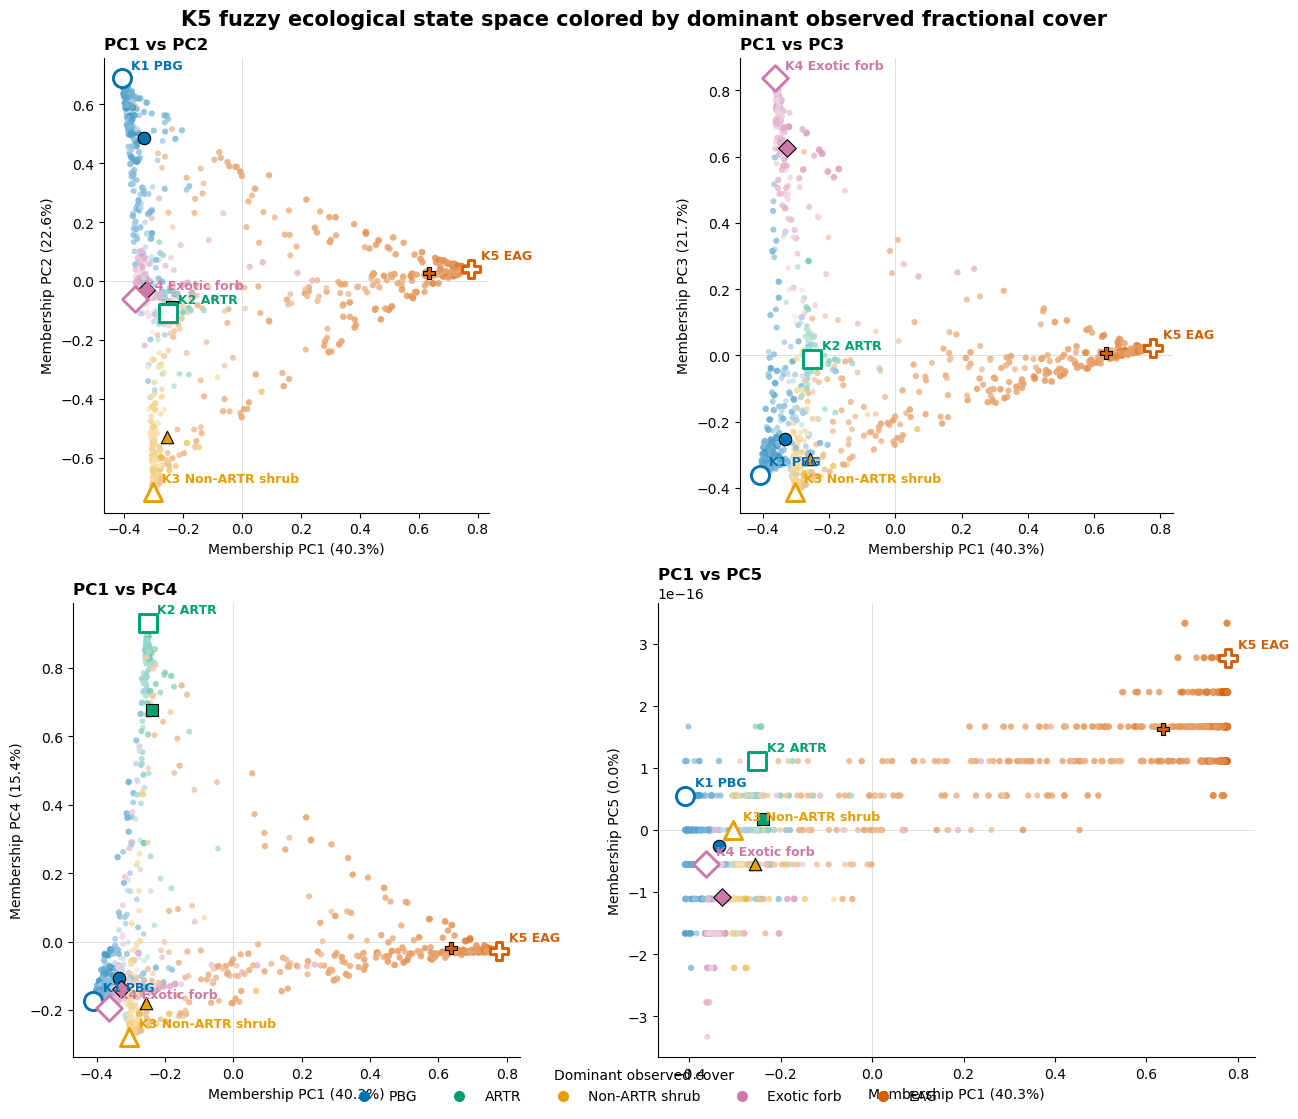

In [ ]:
# ============================================================
# COLOR MEMBERSHIP PCA BY DOMINANT OBSERVED FRACTIONAL COVER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# ------------------------------------------------------------
# 1. Choose the fractional-cover columns to use
#    Adjust these names if your dataframe uses different labels
# ------------------------------------------------------------

fg_cols = [
    "PBG_FG",
    "ARTR_FG",
    "SHRUB_FG",
    "EF_FG",
    "EAG_FG"
]

fg_labels = {
    "PBG_FG": "PBG",
    "ARTR_FG": "ARTR",
    "SHRUB_FG": "Non-ARTR shrub",
    "EF_FG": "Exotic forb",
    "EAG_FG": "EAG"
}

fg_colors = {
    "PBG_FG": "#0072B2",
    "ARTR_FG": "#009E73",
    "SHRUB_FG": "#E69F00",
    "EF_FG": "#CC79A7",
    "EAG_FG": "#D55E00"
}

# ------------------------------------------------------------
# 2. Pull observed fractional cover and identify the dominant FG
# ------------------------------------------------------------

fg = recovered[fg_cols].apply(pd.to_numeric, errors="coerce").copy()

if fg.isna().any().any():
    raise ValueError("Some FG cover values are missing or non-numeric.")

dominant_fg = fg.idxmax(axis=1)
dominant_cover = fg.max(axis=1)

# If cover is recorded as 0–100, normalize to 0–1.
# If already 0–1, this will leave it unchanged.
if dominant_cover.max() > 1.0:
    dominant_cover_scaled = dominant_cover / 100.0
else:
    dominant_cover_scaled = dominant_cover.copy()

dominant_cover_scaled = dominant_cover_scaled.clip(0, 1)

# ------------------------------------------------------------
# 3. Convert dominant FG + cover magnitude into point colors
# ------------------------------------------------------------

def blend_with_white(base_color, strength, min_strength=0.15):
    """
    strength: 0..1
    low values become pale, high values saturated
    """
    rgb = np.array(mcolors.to_rgb(base_color))
    s = min_strength + (1 - min_strength) * strength
    out = (1 - s) * np.ones(3) + s * rgb
    return out

point_colors = np.array([
    blend_with_white(
        fg_colors[fg_name],
        strength=cover_val
    )
    for fg_name, cover_val in zip(dominant_fg, dominant_cover_scaled)
])

# Optional: scale point size slightly by dominant cover as well
point_sizes = 14 + 16 * dominant_cover_scaled.to_numpy()

# ------------------------------------------------------------
# 4. Panel definitions
# ------------------------------------------------------------

panel_defs = [
    (0, 1, "PC1 vs PC2"),
    (0, 2, "PC1 vs PC3"),
    (0, 3, "PC1 vs PC4"),
    (0, 4, "PC1 vs PC5")
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 11),
    constrained_layout=True
)

# ------------------------------------------------------------
# 5. Plot all panels
# ------------------------------------------------------------

for ax, (xpc, ypc, title) in zip(axes.flat, panel_defs):

    # Observation-level points colored by dominant fractional cover
    ax.scatter(
        scores_all[:, xpc],
        scores_all[:, ypc],
        c=point_colors,
        s=point_sizes,
        alpha=0.85,
        edgecolors="none",
        rasterized=True,
        zorder=2
    )

    # Project pure-membership vertices and hard-class centers
    # Retain the cluster symbology here for interpretation
    for k in range(1, 6):

        # Open pure-membership vertex
        ax.scatter(
            vertices_all[k-1, xpc],
            vertices_all[k-1, ypc],
            marker=markers[k],
            s=170,
            facecolors="white",
            edgecolors=colors[k],
            linewidths=2.1,
            zorder=10
        )

        ax.annotate(
            f"K{k} {cluster_names[k]}",
            (
                vertices_all[k-1, xpc],
                vertices_all[k-1, ypc]
            ),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=9,
            weight="semibold",
            color=colors[k],
            zorder=11
        )

        # Mean hard-assigned center
        ax.scatter(
            centers_all[k-1, xpc],
            centers_all[k-1, ypc],
            marker=markers[k],
            s=80,
            c=colors[k],
            edgecolors="black",
            linewidths=0.8,
            zorder=9
        )

    ax.axhline(0, color="0.85", lw=0.6, zorder=0)
    ax.axvline(0, color="0.85", lw=0.6, zorder=0)

    if ypc != 4:
        ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel(f"Membership PC{xpc+1} ({explained_all[xpc]:.1%})")
    ax.set_ylabel(f"Membership PC{ypc+1} ({explained_all[ypc]:.1%})")
    ax.set_title(title, loc="left", fontsize=12, weight="bold")

# ------------------------------------------------------------
# 6. Legend for dominant cover hue
# ------------------------------------------------------------

legend_handles = []
for col in fg_cols:
    legend_handles.append(
        plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            markersize=8,
            markerfacecolor=fg_colors[col],
            markeredgecolor="none",
            label=fg_labels[col]
        )
    )

fig.legend(
    handles=legend_handles,
    title="Dominant observed cover",
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.01)
)

fig.suptitle(
    "K5 fuzzy ecological state space colored by dominant observed fractional cover",
    fontsize=15,
    weight="bold"
)

plt.show()

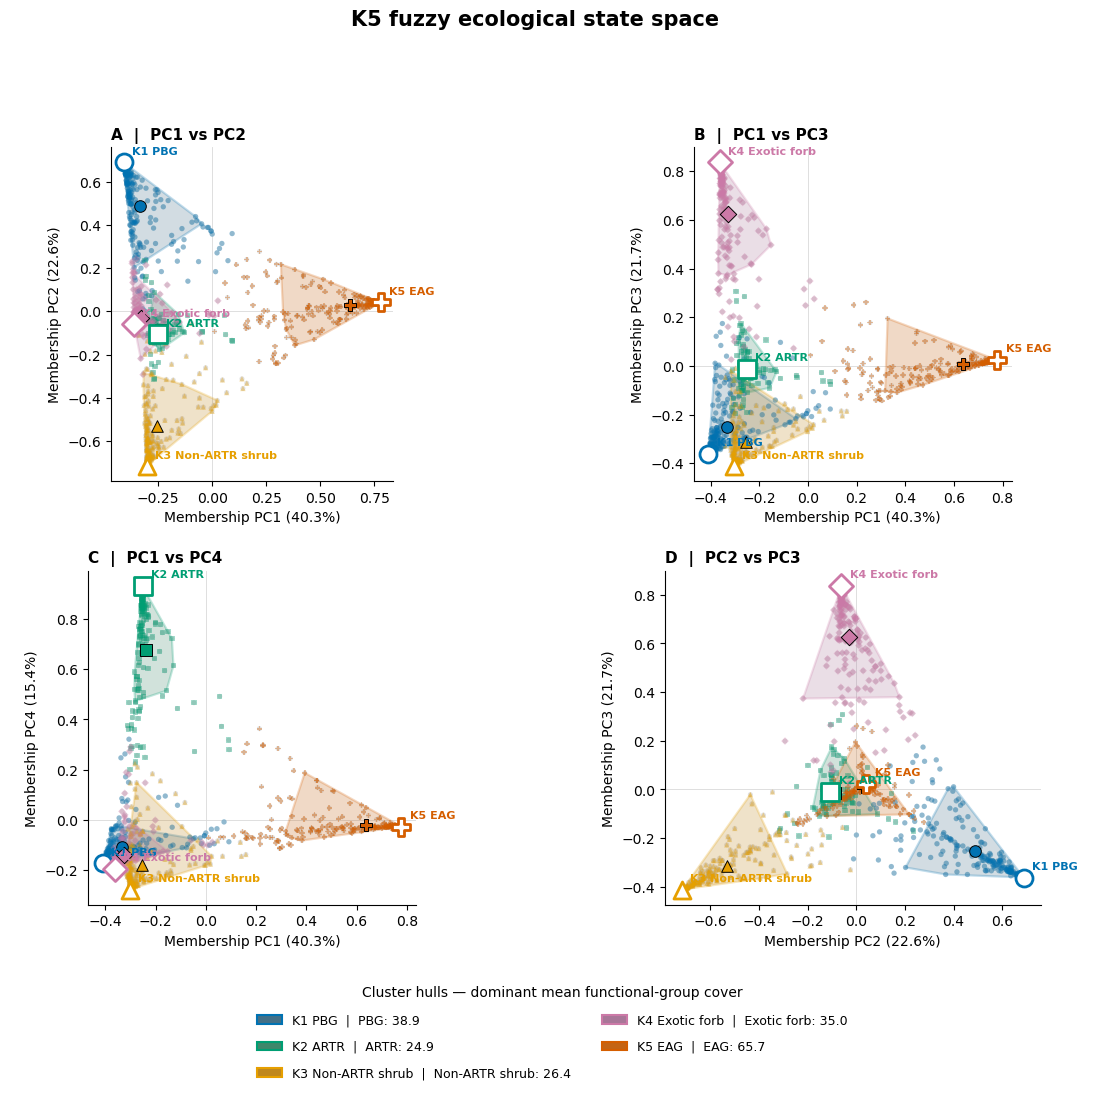

In [ ]:

# ============================================================
# 5–7. PUBLICATION LAYOUT WITH DEDICATED LEGEND ROW
# ============================================================

from matplotlib.gridspec import GridSpec

panel_defs = [
    (0, 1, "A  |  PC1 vs PC2"),
    (0, 2, "B  |  PC1 vs PC3"),
    (0, 3, "C  |  PC1 vs PC4"),
    (1, 2, "D  |  PC2 vs PC3")
]

fig = plt.figure(figsize=(14, 12))

gs = GridSpec(
    3, 2,
    figure=fig,
    height_ratios=[1, 1, 0.23],
    hspace=0.36,
    wspace=0.24
)

axes = [
    fig.add_subplot(gs[0, 0]),
    fig.add_subplot(gs[0, 1]),
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1])
]

legend_ax = fig.add_subplot(gs[2, :])
legend_ax.axis("off")

for ax, (xpc, ypc, title) in zip(axes, panel_defs):

    # Background observations
    ax.scatter(
        scores_all[:, xpc],
        scores_all[:, ypc],
        s=13,
        c="0.72",
        alpha=0.45,
        edgecolors="none",
        rasterized=True,
        zorder=0
    )

    # Core-observation hulls
    for k in range(1, 6):
        mask = (hard == k) & core_mask

        draw_cluster_hull(
            ax,
            scores_all[mask, xpc],
            scores_all[mask, ypc],
            facecolor=cluster_mix_color[k],
            edgecolor=colors[k],
            alpha=0.24,
            lw=1.6,
            zorder=1
        )

    # Colored cluster observations
    for k in range(1, 6):
        mask = hard == k

        ax.scatter(
            scores_all[mask, xpc],
            scores_all[mask, ypc],
            s=15,
            marker=markers[k],
            color=colors[k],
            alpha=0.35,
            edgecolors="none",
            rasterized=True,
            zorder=2
        )

    # Pure vertices and observed cluster centers
    for k in range(1, 6):

        ax.scatter(
            vertices_all[k-1, xpc],
            vertices_all[k-1, ypc],
            marker=markers[k],
            s=150,
            facecolors="white",
            edgecolors=colors[k],
            linewidths=2.0,
            zorder=10
        )

        ax.annotate(
            f"K{k} {cluster_names[k]}",
            (vertices_all[k-1, xpc],
             vertices_all[k-1, ypc]),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=8,
            weight="semibold",
            color=colors[k],
            zorder=11
        )

        ax.scatter(
            centers_all[k-1, xpc],
            centers_all[k-1, ypc],
            marker=markers[k],
            s=70,
            color=colors[k],
            edgecolors="black",
            linewidths=0.7,
            zorder=9
        )

    ax.axhline(0, color="0.85", lw=0.6, zorder=0)
    ax.axvline(0, color="0.85", lw=0.6, zorder=0)

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(
        f"Membership PC{xpc+1} ({explained_all[xpc]:.1%})"
    )
    ax.set_ylabel(
        f"Membership PC{ypc+1} ({explained_all[ypc]:.1%})"
    )
    ax.set_title(title, loc="left", fontsize=11, weight="bold")

# ------------------------------------------------------------
# Legend: dedicated bottom row, two columns
# ------------------------------------------------------------

legend_handles = []

for k in range(1, 6):
    mean_cover = cluster_mean_cover[k]
    dom_fg = mean_cover.idxmax()

    legend_handles.append(
        Patch(
            facecolor=cluster_mix_color[k],
            edgecolor=colors[k],
            linewidth=1.5,
            label=(
                f"K{k} {cluster_names[k]}  |  "
                f"{fg_labels[dom_fg]}: {mean_cover.max():.1f}"
            )
        )
    )

legend_ax.legend(
    handles=legend_handles,
    loc="center",
    ncol=2,
    frameon=False,
    fontsize=9,
    title="Cluster hulls — dominant mean functional-group cover",
    title_fontsize=10,
    columnspacing=2.5,
    handlelength=2.0,
    labelspacing=1.1
)

fig.suptitle(
    "K5 fuzzy ecological state space",
    fontsize=15,
    fontweight="bold",
    y=0.995
)

plt.show()


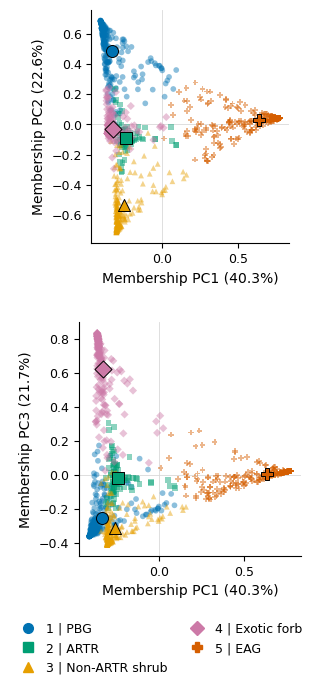

In [ ]:
# ============================================================
# K5 MEMBERSHIP PCA — SHARED LEGEND, 7 INCHES TALL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA

# Same PCA calculation as the working cell.
pca_all = PCA(n_components=5)
scores_all = pca_all.fit_transform(U)
vertices_all = pca_all.transform(np.eye(5))
explained_all = pca_all.explained_variance_ratio_

centers_all = np.vstack([
    scores_all[hard == k].mean(axis=0)
    for k in range(1, 6)
])

fig, axes = plt.subplots(
    2, 1,
    figsize=(4.5, 7.0),
)

for ax, pc_y in zip(axes, [1, 2]):

    # Individual observations.
    for k in range(1, 6):
        mask = hard == k

        ax.scatter(
            scores_all[mask, 0],
            scores_all[mask, pc_y],
            s=17,
            marker=markers[k],
            color=colors[k],
            alpha=0.45,
            edgecolors="none",
            rasterized=False,
            zorder=2,
        )

    # Pure-membership vertices and observed centroids.
    for k in range(1, 6):

 #       ax.scatter(
 #           vertices_all[k - 1, 0],
 #           vertices_all[k - 1, pc_y],
 #           marker=markers[k],
 #           s=155,
 #           facecolors="white",
 #           edgecolors=colors[k],
 #           linewidths=2,
 #           zorder=10,
 #       )

        ax.scatter(
            centers_all[k - 1, 0],
            centers_all[k - 1, pc_y],
            marker=markers[k],
            s=75,
            color=colors[k],
            edgecolors="black",
            linewidths=0.7,
            zorder=9,
        )

    ax.axhline(0, color="0.85", lw=0.6, zorder=0)
    ax.axvline(0, color="0.85", lw=0.6, zorder=0)

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(
        f"Membership PC1 ({explained_all[0]:.1%})",
        fontsize=10,
    )
    ax.set_ylabel(
        f"Membership PC{pc_y + 1} ({explained_all[pc_y]:.1%})",
        fontsize=10,
    )
    ax.tick_params(axis="both", labelsize=9)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

# One shared legend; names are removed from both plotting regions.
legend_handles = [
    Line2D(
        [], [],
        linestyle="none",
        marker=markers[k],
        markersize=7,
        markerfacecolor=colors[k],
        markeredgecolor=colors[k],
        label=f"{k} | {cluster_names[k]}",
    )
    for k in range(1, 6)
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=2,
    frameon=False,
    fontsize=9,
    handletextpad=0.5,
    columnspacing=1.3,
    labelspacing=0.5,
)

fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.20,
    top=0.98,
    hspace=0.34,
)

#fig.savefig("K5_PCA_compact.svg", facecolor="white")
plt.show()

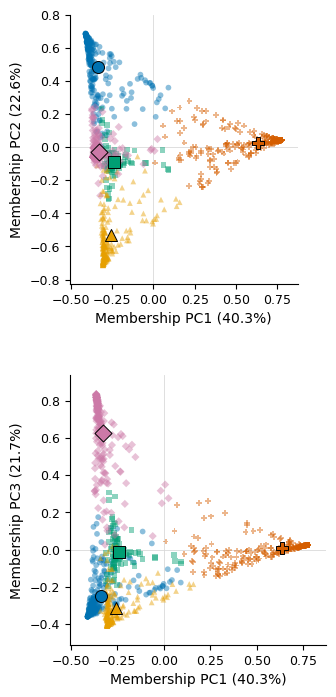

In [34]:
# ============================================================
# K5 MEMBERSHIP PCA — LEFT-ALIGNED, 7 INCHES TALL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Same PCA calculation as the working cell.
pca_all = PCA(n_components=5)
scores_all = pca_all.fit_transform(U)
vertices_all = pca_all.transform(np.eye(5))
explained_all = pca_all.explained_variance_ratio_

centers_all = np.vstack([
    scores_all[hard == k].mean(axis=0)
    for k in range(1, 6)
])

fig, axes = plt.subplots(
    2, 1,
    figsize=(4.5, 7.0),
)

for ax, pc_y in zip(axes, [1, 2]):

    # Individual observations.
    for k in range(1, 6):
        mask = hard == k

        ax.scatter(
            scores_all[mask, 0],
            scores_all[mask, pc_y],
            s=17,
            marker=markers[k],
            color=colors[k],
            alpha=0.45,
            edgecolors="none",
            rasterized=False,
            zorder=2,
        )

    # Observed centroids.
    for k in range(1, 6):
        ax.scatter(
            centers_all[k - 1, 0],
            centers_all[k - 1, pc_y],
            marker=markers[k],
            s=75,
            color=colors[k],
            edgecolors="black",
            linewidths=0.7,
            zorder=9,
        )

    ax.axhline(0, color="0.85", lw=0.6, zorder=0)
    ax.axvline(0, color="0.85", lw=0.6, zorder=0)

    # Autoscale to the plotted data with a little extra padding.
    ax.margins(x=0.08, y=0.08)

    # Preserve data limits; resize each box and align its left edge.
    ax.set_aspect("equal", adjustable="box")
    ax.set_anchor("W")

    ax.set_xlabel(
        f"Membership PC1 ({explained_all[0]:.1%})",
        fontsize=10,
    )
    ax.set_ylabel(
        f"Membership PC{pc_y + 1} ({explained_all[pc_y]:.1%})",
        fontsize=10,
    )
    ax.tick_params(axis="both", labelsize=9)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

fig.subplots_adjust(
    left=0.18,
    right=0.96,
    bottom=0.08,
    top=0.98,
    hspace=0.34,
)

# Uncomment to export the 4.5 × 7-inch vector figure.
# fig.savefig("K5_PCA_compact.svg", facecolor="white")

plt.show()